# Tech Challenge — Fase 4
## Monitoramento Médico Multimodal com Inteligência Artificial

### 1. Preparação do Ambiente

Este projeto tem como objetivo desenvolver uma prova de conceito para monitoramento médico multimodal, utilizando técnicas de visão computacional, processamento de áudio, análise de linguagem natural e detecção de anomalias.

A solução é desenvolvida em Python, utilizando:

- **OpenCV e MediaPipe Pose** para análise postural (equivalente leve ao OpenPose, executável no Colab sem compilação).
- **YOLOv8** (Ultralytics) para detecção de objetos e áreas críticas na cena.
- **OpenAI Whisper** e **Azure Speech to Text** para transcrição de áudio.
- **pysentimiento** e **Azure AI Language** (sentimento e *Text Analytics for Health*) para análise textual.
- **Pandas, NumPy, scikit-learn e wfdb (PhysioNet)** para detecção de anomalias em dados clínicos.
- Regras de fusão para consolidação das evidências e geração de alertas à equipe médica.

> **Ordem de execução:** rode a célula de instalação, depois **Ambiente de execução → Reiniciar sessão** e então execute o restante do notebook em sequência.

### 1.0 Instalação de dependências

In [1]:
# Instalação única de dependências (Colab já possui torch, transformers, opencv e ffmpeg).
# O gTTS foi removido: ele exige click<8.2 e conflita com o spacy instalado pelo pysentimiento.
%pip install -q mediapipe openai-whisper librosa soundfile edge-tts pydub pysentimiento wfdb ultralytics yt-dlp azure-cognitiveservices-speech azure-ai-textanalytics

### 1.1 Verificação do ambiente e credenciais

Verifica versões das bibliotecas, GPU e ffmpeg, e define `obter_segredo`, que lê credenciais de
variáveis de ambiente ou dos *Secrets* do Colab (ícone de chave na barra lateral). Nenhuma chave
deve ser escrita diretamente no notebook.

In [2]:
import os
import sys
import shutil
import platform
import importlib

import torch

try:
    import google.colab  # noqa: F401
    EM_COLAB = True
except ImportError:
    EM_COLAB = False


def obter_segredo(nome, padrao=""):
    """Lê uma credencial de variável de ambiente ou dos Secrets do Colab."""
    valor = os.getenv(nome)
    if valor:
        return valor
    if EM_COLAB:
        try:
            from google.colab import userdata
            return userdata.get(nome) or padrao
        except Exception:
            return padrao
    return padrao


print("=" * 50)
print("AMBIENTE DE EXECUÇÃO")
print("=" * 50)
print(f"Python   : {platform.python_version()}")
print(f"Sistema  : {platform.system()} {platform.release()}")
print(f"Colab    : {EM_COLAB}")

bibliotecas = [
    "numpy", "pandas", "sklearn", "cv2", "mediapipe", "ultralytics", "whisper",
    "librosa", "edge_tts", "pydub", "pysentimiento", "wfdb", "torch",
]
for nome in bibliotecas:
    try:
        modulo = importlib.import_module(nome)
        print(f"{nome:<14}: {getattr(modulo, '__version__', 'instalado')}")
    except Exception as erro:
        print(f"{nome:<14}: NÃO DISPONÍVEL ({erro})")

print("-" * 50)
GPU_DISPONIVEL = torch.cuda.is_available()
DEVICE = "cuda" if GPU_DISPONIVEL else "cpu"
print(f"GPU disponível: {GPU_DISPONIVEL}")
if GPU_DISPONIVEL:
    print(f"GPU: {torch.cuda.get_device_name(0)}")

for programa in ["ffmpeg", "ffprobe"]:
    print(f"{programa:<8} disponível: {shutil.which(programa) is not None}")

AZURE_CONFIGURADO = all(
    obter_segredo(n) for n in
    ["AZURE_SPEECH_KEY", "AZURE_SPEECH_REGION", "AZURE_LANGUAGE_KEY", "AZURE_LANGUAGE_ENDPOINT"]
)
print(f"Credenciais Azure configuradas: {AZURE_CONFIGURADO}")

AMBIENTE DE EXECUÇÃO
Python   : 3.11.9
Sistema  : Windows 10
Colab    : False
numpy         : 2.4.6


pandas        : 3.1.1


sklearn       : 1.9.1
cv2           : 5.1.0


mediapipe     : 1.2.3
ultralytics   : 8.4.215


whisper       : 20250625
librosa       : 0.11.0


edge_tts      : 7.3.1
pydub         : instalado


pysentimiento : instalado
wfdb          : 4.3.1
torch         : 2.14.1+cu126
--------------------------------------------------
GPU disponível: True
GPU: NVIDIA GeForce RTX 3060
ffmpeg   disponível: True
ffprobe  disponível: True
Credenciais Azure configuradas: False


## 2. Análise de Vídeo — Detecção de Movimentos Corporais

Este módulo utiliza técnicas de visão computacional para identificar pontos anatômicos e analisar movimentos corporais em vídeos.

O processamento é baseado em OpenCV e MediaPipe, permitindo:

- Leitura e processamento dos frames de um vídeo.
- Identificação de pontos corporais.
- Reconhecimento do movimento de elevação dos braços.
- Contagem de movimentos realizados.
- Geração de um vídeo com as detecções realizadas.

A detecção de movimentos utiliza a posição relativa dos cotovelos e dos olhos, considerando o sistema de coordenadas da imagem.

Os resultados servirão como base para a identificação posterior de padrões de movimento incomuns.

### 2.1 Detecção de poses e contagem de movimentos

O vídeo será processado quadro a quadro utilizando OpenCV e MediaPipe.

Para cada quadro, o modelo identificará pontos anatômicos e verificará a posição dos cotovelos em relação aos olhos.

Um movimento será contabilizado quando pelo menos um cotovelo passar para uma posição acima dos olhos, desde que o braço não esteja previamente identificado como levantado.

Ao final, será gerado um vídeo com as marcações corporais e a quantidade de movimentos detectados.

A contagem representa uma medida de movimento corporal e não constitui, isoladamente, uma avaliação clínica.

#### Localização dos vídeos

Os vídeos são procurados em `/content`, no Google Drive (se `MONTAR_DRIVE = True`), na pasta
indicada pela variável de ambiente `PASTA_VIDEOS` e no diretório atual. No Colab, se o vídeo
principal não for encontrado, é solicitado o upload. Montar o Drive evita o upload lento de
arquivos grandes.

In [3]:
import os
import glob

NOMES_VIDEOS = ["E01_P01_AF_VFL_GM.mp4", "E01_P01_AF_VHJ_GM.mp4"]
MONTAR_DRIVE = False

if EM_COLAB and MONTAR_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

PASTAS_BUSCA = [p for p in [os.getenv("PASTA_VIDEOS"), "/content", ".", "Fase 4"] if p]


def localizar_video(nome):
    for pasta in PASTAS_BUSCA:
        candidato = os.path.join(pasta, nome)
        if os.path.exists(candidato):
            return os.path.abspath(candidato)
    if os.path.isdir("/content/drive/MyDrive"):
        achados = glob.glob(f"/content/drive/MyDrive/**/{nome}", recursive=True)
        if achados:
            return achados[0]
    return None


VIDEO_PATH = localizar_video(NOMES_VIDEOS[0])
VIDEO_PATH_2 = localizar_video(NOMES_VIDEOS[1])

# Vídeo com execuções corretas e incorretas rotuladas por fisioterapeuta (dataset REHAB24-6)
NOME_VIDEO_ERROS = "REHAB24-6_Ex1_PM_001_abducao.mp4"
NOME_ROTULOS_ERROS = "REHAB24-6_Segmentation.csv"
VIDEO_PATH_3 = localizar_video(NOME_VIDEO_ERROS)
ROTULOS_PATH_3 = localizar_video(NOME_ROTULOS_ERROS)

if VIDEO_PATH is None and EM_COLAB:
    from google.colab import files as _files
    print("Vídeo principal não encontrado. Selecione o arquivo para upload...")
    enviados = _files.upload()
    if enviados:
        VIDEO_PATH = os.path.abspath(list(enviados.keys())[0])

if VIDEO_PATH is None:
    raise FileNotFoundError(
        f"Vídeo {NOMES_VIDEOS[0]} não encontrado. Ajuste PASTAS_BUSCA ou PASTA_VIDEOS."
    )

print(f"Vídeo principal : {VIDEO_PATH}")
print(f"Vídeo comparação: {VIDEO_PATH_2 or 'não encontrado (comparação será ignorada)'}")
print(f"Vídeo com erros : {VIDEO_PATH_3 or 'não encontrado (avaliação com rótulos será ignorada)'}")

Vídeo principal : E01_P01_AF_VFL_GM.mp4
Vídeo comparação: E01_P01_AF_VHJ_GM.mp4
Vídeo com erros : REHAB24-6_Ex1_PM_001_abducao.mp4


In [4]:
import os
import urllib.request

import cv2
import mediapipe as mp
import pandas as pd

from tqdm.auto import tqdm

# --------------------------------------------------
# 1. Modelo de detecção de poses
# --------------------------------------------------

modelo_path = "pose_landmarker_lite.task"

if not os.path.exists(modelo_path):
    url_modelo = (
        "https://storage.googleapis.com/mediapipe-models/"
        "pose_landmarker/pose_landmarker_lite/float16/1/"
        "pose_landmarker_lite.task"
    )
    urllib.request.urlretrieve(url_modelo, modelo_path)

BaseOptions = mp.tasks.BaseOptions
PoseLandmarker = mp.tasks.vision.PoseLandmarker
PoseLandmarkerOptions = mp.tasks.vision.PoseLandmarkerOptions
RunningMode = mp.tasks.vision.RunningMode

options = PoseLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=modelo_path),
    running_mode=RunningMode.VIDEO,
    num_poses=1
)

# --------------------------------------------------
# 2. Pontos anatômicos
# --------------------------------------------------

LEFT_EYE = 2
RIGHT_EYE = 5

LEFT_SHOULDER = 11
RIGHT_SHOULDER = 12

LEFT_ELBOW = 13
RIGHT_ELBOW = 14

LEFT_WRIST = 15
RIGHT_WRIST = 16

LEFT_HIP = 23
RIGHT_HIP = 24

# Conexões utilizadas para desenhar o esqueleto
CONEXOES = [
    (conexao.start, conexao.end)
    for conexao in
    mp.tasks.vision.PoseLandmarksConnections.POSE_LANDMARKS
]

# --------------------------------------------------
# 3. Análise da posição dos braços
# --------------------------------------------------

def analisar_braco(landmarks, lado):

    if lado == "esquerdo":
        ombro = landmarks[LEFT_SHOULDER].y
        cotovelo = landmarks[LEFT_ELBOW].y
        punho = landmarks[LEFT_WRIST].y
        quadril = landmarks[LEFT_HIP].y
        olho = landmarks[LEFT_EYE].y

    else:
        ombro = landmarks[RIGHT_SHOULDER].y
        cotovelo = landmarks[RIGHT_ELBOW].y
        punho = landmarks[RIGHT_WRIST].y
        quadril = landmarks[RIGHT_HIP].y
        olho = landmarks[RIGHT_EYE].y

    # Normalização pela altura do tronco
    altura_tronco = max(quadril - ombro, 0.01)

    # Detectar tentativa de elevação do braço
    elevacao = (
        punho < quadril - 0.45 * altura_tronco
    )

    # Critério de repetição válida
    altura_valida = cotovelo <= olho

    # Detectar retorno à posição inicial
    retorno = (
        punho > quadril - 0.15 * altura_tronco
    )

    return elevacao, altura_valida, retorno


# --------------------------------------------------
# 4. Abrir o vídeo
# --------------------------------------------------

caminho_video = VIDEO_PATH  # definido em "Localização dos vídeos"

cap = cv2.VideoCapture(caminho_video)

if not cap.isOpened():
    raise ValueError("Não foi possível abrir o vídeo.")

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS) or 30
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

output_path = "video_pose_classificado.mp4"

fourcc = cv2.VideoWriter_fourcc(*"mp4v")

out = cv2.VideoWriter(
    output_path,
    fourcc,
    fps,
    (width, height)
)

# --------------------------------------------------
# 5. Variáveis de controle
# --------------------------------------------------

estado_bracos = {
    "esquerdo": {
        "em_execucao": False,
        "atingiu_altura": False
    },
    "direito": {
        "em_execucao": False,
        "atingiu_altura": False
    }
}

repeticoes_validas = 0
repeticoes_anomalas = 0
frames_processados = 0

registros_repeticoes = []
tempos_movimentos = []

# --------------------------------------------------
# 6. Processamento do vídeo
# --------------------------------------------------

with PoseLandmarker.create_from_options(options) as landmarker:

    for frame_idx in tqdm(
        range(total_frames),
        desc="Processando vídeo"
    ):

        ret, frame = cap.read()

        if not ret:
            break

        # Converter frame para RGB
        rgb_frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=rgb_frame
        )

        timestamp_ms = int(frame_idx * 1000 / fps)

        # Detectar pose corporal
        results = landmarker.detect_for_video(
            mp_image,
            timestamp_ms
        )

        if results.pose_landmarks:

            landmarks = results.pose_landmarks[0]

            # Desenhar pontos corporais
            for landmark in landmarks:

                x = int(landmark.x * width)
                y = int(landmark.y * height)

                cv2.circle(
                    frame,
                    (x, y),
                    3,
                    (0, 255, 0),
                    -1
                )

            # Desenhar conexões corporais
            for inicio, fim in CONEXOES:

                p1 = landmarks[inicio]
                p2 = landmarks[fim]

                cv2.line(
                    frame,
                    (
                        int(p1.x * width),
                        int(p1.y * height)
                    ),
                    (
                        int(p2.x * width),
                        int(p2.y * height)
                    ),
                    (255, 255, 255),
                    2
                )

            # --------------------------------------
            # Analisar cada braço separadamente
            # --------------------------------------

            tempo_atual = frame_idx / fps

            for lado in ["esquerdo", "direito"]:

                elevacao, altura_valida, retorno = (
                    analisar_braco(landmarks, lado)
                )

                estado = estado_bracos[lado]

                # Início de uma tentativa
                if elevacao and not estado["em_execucao"]:

                    estado["em_execucao"] = True
                    estado["atingiu_altura"] = False

                # Acompanhar a tentativa
                if estado["em_execucao"]:

                    if altura_valida:
                        estado["atingiu_altura"] = True

                    # Finalizar quando o braço retornar
                    if retorno:

                        if estado["atingiu_altura"]:

                            repeticoes_validas += 1
                            classificacao = "Valida"

                        else:

                            repeticoes_anomalas += 1
                            classificacao = "Potencial anomalia"

                        registros_repeticoes.append({
                            "repeticao": len(registros_repeticoes) + 1,
                            "braco": lado,
                            "tempo_segundos": round(
                                tempo_atual, 2
                            ),
                            "classificacao": classificacao
                        })

                        tempos_movimentos.append(
                            tempo_atual
                        )

                        estado["em_execucao"] = False
                        estado["atingiu_altura"] = False

        # ------------------------------------------
        # Exibir contadores no vídeo
        # ------------------------------------------

        cv2.putText(
            frame,
            f"Repeticoes validas: {repeticoes_validas}",
            (10, 30),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 255, 0),
            2
        )

        cv2.putText(
            frame,
            f"Potenciais anomalias: {repeticoes_anomalas}",
            (10, 60),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 0, 255),
            2
        )

        out.write(frame)
        frames_processados += 1

# --------------------------------------------------
# 7. Finalização
# --------------------------------------------------

cap.release()
out.release()

# --------------------------------------------------
# 8. Resultados
# --------------------------------------------------

df_repeticoes = pd.DataFrame(
    registros_repeticoes,
    columns=[
        "repeticao",
        "braco",
        "tempo_segundos",
        "classificacao"
    ]
)

total_repeticoes = (
    repeticoes_validas + repeticoes_anomalas
)

print("=" * 50)
print("RESULTADO DA ANÁLISE DE MOVIMENTOS")
print("=" * 50)

print(f"Frames processados: {frames_processados}")
print(f"Total de repetições: {total_repeticoes}")
print(f"Repetições válidas: {repeticoes_validas}")
print(f"Potenciais anomalias: {repeticoes_anomalas}")
print(f"Vídeo gerado: {output_path}")

display(df_repeticoes)

RESULTADO DA ANÁLISE DE MOVIMENTOS
Frames processados: 909
Total de repetições: 9
Repetições válidas: 9
Potenciais anomalias: 0
Vídeo gerado: video_pose_classificado.mp4


,repeticao,braco,tempo_segundos,classificacao
0,1,direito,1.71,Valida
1,2,direito,4.89,Valida
2,3,direito,8.47,Valida
3,4,direito,11.75,Valida
4,5,direito,15.10,Valida
5,6,direito,18.55,Valida
6,7,direito,21.60,Valida
7,8,direito,24.88,Valida
8,9,direito,27.86,Valida


### 2.2 Identificação de movimentos potencialmente anômalos

A identificação de anomalias utiliza os registros de movimentos obtidos durante o processamento do vídeo.

Para cada movimento detectado, é registrado seu instante de ocorrência em segundos. A partir desses registros, são calculados os intervalos entre movimentos consecutivos.

Movimentos realizados em intervalos inferiores a um limite experimental são classificados como potenciais anomalias e registrados para análise posterior.

Essa abordagem utiliza regras baseadas em tempo, sem necessidade de treinamento adicional de modelos. Os alertas produzidos representam indicadores experimentais e não constituem diagnósticos clínicos.

In [5]:
import pandas as pd

# Limite experimental entre repetições
intervalo_minimo = 1.0

# Dados gerados na etapa 2.1
df_movimentos = df_repeticoes.copy()

# Calcular intervalo entre repetições concluídas
df_movimentos["intervalo_segundos"] = (
    df_movimentos["tempo_segundos"]
    .diff()
    .round(2)
)

# Identificar anomalias de amplitude
df_movimentos["anomalia_amplitude"] = (
    df_movimentos["classificacao"] == "Potencial anomalia"
)

# Identificar anomalias temporais
df_movimentos["anomalia_temporal"] = (
    df_movimentos["intervalo_segundos"] < intervalo_minimo
)

# Consolidar os resultados
def classificar_movimento(linha):

    amplitude = linha["anomalia_amplitude"]
    temporal = linha["anomalia_temporal"]

    if amplitude and temporal:
        return "Anomalia de amplitude e temporal"

    if amplitude:
        return "Anomalia de amplitude"

    if temporal:
        return "Anomalia temporal"

    return "Normal"


df_movimentos["status"] = df_movimentos.apply(
    classificar_movimento,
    axis=1
)

# Filtrar repetições com anomalias
df_alertas_movimento = df_movimentos[
    df_movimentos["status"] != "Normal"
].copy()

# Organizar colunas
df_movimentos = df_movimentos[
    [
        "repeticao",
        "braco",
        "tempo_segundos",
        "intervalo_segundos",
        "anomalia_amplitude",
        "anomalia_temporal",
        "status"
    ]
]

# Exibir resultados
print("=" * 50)
print("ANÁLISE DE MOVIMENTOS")
print("=" * 50)

print(f"Total de repetições: {len(df_movimentos)}")
print(f"Anomalias de amplitude: {df_movimentos['anomalia_amplitude'].sum()}")
print(f"Anomalias temporais: {df_movimentos['anomalia_temporal'].sum()}")
print(f"Repetições com anomalias: {len(df_alertas_movimento)}")

display(df_movimentos)

ANÁLISE DE MOVIMENTOS
Total de repetições: 9
Anomalias de amplitude: 0
Anomalias temporais: 0
Repetições com anomalias: 0


,repeticao,braco,tempo_segundos,intervalo_segundos,anomalia_amplitude,anomalia_temporal,status
0,1,direito,1.71,NaN,False,False,Normal
1,2,direito,4.89,3.18,False,False,Normal
2,3,direito,8.47,3.58,False,False,Normal
3,4,direito,11.75,3.28,False,False,Normal
4,5,direito,15.10,3.35,False,False,Normal
5,6,direito,18.55,3.45,False,False,Normal
6,7,direito,21.60,3.05,False,False,Normal
7,8,direito,24.88,3.28,False,False,Normal
8,9,direito,27.86,2.98,False,False,Normal


### 2.3 Amplitude articular e comparação entre execuções

A contagem de repetições da seção 2.1 é complementada por uma métrica clínica de reabilitação:
o **ângulo de flexão do ombro** (ângulo entre tronco e braço, no ombro), calculado quadro a quadro
a partir dos pontos do MediaPipe em coordenadas de pixel.

Para cada repetição são registrados o ângulo máximo atingido, a duração e o ritmo. São processados:

| Vídeo | Exercício | Origem |
|---|---|---|
| `E01_P01_AF_VFL_GM.mp4` / `E01_P01_AF_VHJ_GM.mp4` | Flexão do ombro (braço até acima da cabeça) | Vídeos do grupo |
| `REHAB24-6_Ex1_PM_001_abducao.mp4` | Abdução do ombro (elevação lateral) — 5 repetições corretas e 5 incorretas | Dataset REHAB24-6 |

Como cada exercício tem uma amplitude-alvo diferente, os limites ficam em `PERFIS_EXERCICIO`:

- **Flexão:** repetição válida exige cotovelo acima do olho (regra da seção 2.1) e ângulo ≥ 150°;
- **Abdução:** repetição válida exige ângulo ≥ 127°. **Este limiar foi calibrado com os rótulos do
  próprio vídeo** (corretas: 129–136°; incorretas: 119–125°); na prática clínica, a amplitude-alvo
  é definida pelo fisioterapeuta para cada paciente;
- **Ritmo irregular:** coeficiente de variação dos intervalos entre repetições acima de `CV_MAXIMO_RITMO`.

> Dataset: Černek, A.; Sedmidubsky, J.; Budikova, P. *REHAB24-6: Physical Therapy Dataset for
> Analyzing Pose Estimation Methods*. SISAP 2024. Zenodo, DOI 10.5281/zenodo.13305826
> (CC BY-NC 4.0, uso acadêmico não comercial).

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CV_MAXIMO_RITMO = 0.25       # coeficiente de variação dos intervalos (experimental)

# Amplitude-alvo por exercício (graus). Na prática, definida pelo fisioterapeuta.
PERFIS_EXERCICIO = {
    "flexao": {"descricao": "Flexão do ombro", "angulo_minimo": 150, "exige_cotovelo_acima_olho": True},
    "abducao": {"descricao": "Abdução do ombro", "angulo_minimo": 127, "exige_cotovelo_acima_olho": False},
}
VIDEOS_ANALISADOS = [
    (VIDEO_PATH, "flexao"),
    (VIDEO_PATH_2, "flexao"),
    (VIDEO_PATH_3, "abducao"),
]

PONTOS_LADO = {
    "esquerdo": (LEFT_SHOULDER, LEFT_ELBOW, LEFT_HIP),
    "direito": (RIGHT_SHOULDER, RIGHT_ELBOW, RIGHT_HIP),
}


def angulo_ombro(landmarks, lado, largura, altura):
    """Ângulo (graus) entre o vetor ombro→quadril e o vetor ombro→cotovelo."""
    i_ombro, i_cotovelo, i_quadril = PONTOS_LADO[lado]
    p = lambda i: np.array([landmarks[i].x * largura, landmarks[i].y * altura])
    v_tronco = p(i_quadril) - p(i_ombro)
    v_braco = p(i_cotovelo) - p(i_ombro)
    cos = np.dot(v_tronco, v_braco) / (np.linalg.norm(v_tronco) * np.linalg.norm(v_braco) + 1e-9)
    return float(np.degrees(np.arccos(np.clip(cos, -1.0, 1.0))))


def analisar_execucao(caminho, perfil="flexao"):
    """Processa um vídeo e retorna repetições (com ângulo máximo) e o histórico por quadro."""
    config = PERFIS_EXERCICIO[perfil]
    cap = cv2.VideoCapture(caminho)
    if not cap.isOpened():
        raise ValueError(f"Não foi possível abrir o vídeo {caminho}.")
    fps_v = cap.get(cv2.CAP_PROP_FPS) or 30
    total_v = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    larg = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    alt = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    estado = {lado: {"em_execucao": False, "atingiu_altura": False, "angulo_max": 0.0, "inicio": 0.0}
              for lado in PONTOS_LADO}
    repeticoes, historico = [], []

    with PoseLandmarker.create_from_options(options) as lm:
        for idx in tqdm(range(total_v), desc=os.path.basename(caminho)):
            ok, quadro = cap.read()
            if not ok:
                break
            imagem = mp.Image(image_format=mp.ImageFormat.SRGB,
                              data=cv2.cvtColor(quadro, cv2.COLOR_BGR2RGB))
            res = lm.detect_for_video(imagem, int(idx * 1000 / fps_v))
            if not res.pose_landmarks:
                continue

            pts = res.pose_landmarks[0]
            t = idx / fps_v
            angulos = {lado: angulo_ombro(pts, lado, larg, alt) for lado in PONTOS_LADO}
            historico.append({
                "frame": idx, "tempo_segundos": t,
                "punho_esq_x": pts[LEFT_WRIST].x, "punho_esq_y": pts[LEFT_WRIST].y,
                "punho_dir_x": pts[RIGHT_WRIST].x, "punho_dir_y": pts[RIGHT_WRIST].y,
                "angulo_esq": angulos["esquerdo"], "angulo_dir": angulos["direito"],
            })

            for lado in PONTOS_LADO:
                elevacao, altura_valida, retorno = analisar_braco(pts, lado)
                e = estado[lado]
                if elevacao and not e["em_execucao"]:
                    e.update(em_execucao=True, atingiu_altura=False, angulo_max=0.0, inicio=t)
                if e["em_execucao"]:
                    e["angulo_max"] = max(e["angulo_max"], angulos[lado])
                    if altura_valida:
                        e["atingiu_altura"] = True
                    if retorno:
                        altura_ok = e["atingiu_altura"] or not config["exige_cotovelo_acima_olho"]
                        amplitude_ok = e["angulo_max"] >= config["angulo_minimo"]
                        repeticoes.append({
                            "braco": lado,
                            "inicio_segundos": round(e["inicio"], 2),
                            "fim_segundos": round(t, 2),
                            "duracao_segundos": round(t - e["inicio"], 2),
                            "angulo_max_graus": round(e["angulo_max"], 1),
                            "classificacao": "Valida" if (altura_ok and amplitude_ok) else "Potencial anomalia",
                        })
                        e["em_execucao"] = False

    cap.release()
    df_rep = pd.DataFrame(repeticoes, columns=[
        "braco", "inicio_segundos", "fim_segundos", "duracao_segundos",
        "angulo_max_graus", "classificacao"])
    info = {"fps": fps_v, "duracao_segundos": total_v / fps_v, "perfil": perfil,
            "angulo_minimo": config["angulo_minimo"]}
    return df_rep, pd.DataFrame(historico), info


def resumir_execucao(nome, df_rep, info):
    intervalos = df_rep["fim_segundos"].diff().dropna()
    cv = float(intervalos.std() / intervalos.mean()) if len(intervalos) > 1 else 0.0
    return {
        "video": nome,
        "exercicio": PERFIS_EXERCICIO[info["perfil"]]["descricao"],
        "angulo_alvo": info["angulo_minimo"],
        "duracao_segundos": round(info["duracao_segundos"], 1),
        "repeticoes": len(df_rep),
        "validas": int((df_rep["classificacao"] == "Valida").sum()),
        "potenciais_anomalias": int((df_rep["classificacao"] != "Valida").sum()),
        "braco_predominante": df_rep["braco"].mode().iat[0] if len(df_rep) else "-",
        "angulo_max_medio": round(float(df_rep["angulo_max_graus"].mean()), 1) if len(df_rep) else None,
        "angulo_max_minimo": round(float(df_rep["angulo_max_graus"].min()), 1) if len(df_rep) else None,
        "reps_amplitude_incompleta": int((df_rep["angulo_max_graus"] < info["angulo_minimo"]).sum()),
        "intervalo_medio_segundos": round(float(intervalos.mean()), 2) if len(intervalos) else None,
        "cv_ritmo": round(cv, 3),
        "ritmo_irregular": cv > CV_MAXIMO_RITMO,
    }


execucoes = {}
for caminho, perfil in VIDEOS_ANALISADOS:
    if caminho:
        nome = os.path.basename(caminho)
        execucoes[nome] = analisar_execucao(caminho, perfil)

df_comparacao = pd.DataFrame([
    resumir_execucao(nome, df_rep, info) for nome, (df_rep, _, info) in execucoes.items()
])

print("=" * 50)
print("COMPARAÇÃO ENTRE EXECUÇÕES")
print("=" * 50)
display(df_comparacao.set_index("video").T)

for nome, (df_rep, _, _) in execucoes.items():
    print(f"\nRepetições — {nome}")
    display(df_rep)

COMPARAÇÃO ENTRE EXECUÇÕES


video,E01_P01_AF_VFL_GM.mp4,E01_P01_AF_VHJ_GM.mp4,REHAB24-6_Ex1_PM_001_abducao.mp4
exercicio,Flexão do ombro,Flexão do ombro,Abdução do ombro
angulo_alvo,150,150,127
duracao_segundos,30.4,28.9,100.5
repeticoes,9,9,12
validas,9,9,5
potenciais_anomalias,0,0,7
braco_predominante,direito,direito,direito
angulo_max_medio,173.6,172.1,123.4
angulo_max_minimo,172.4,169.0,102.9
reps_amplitude_incompleta,0,0,7



Repetições — E01_P01_AF_VFL_GM.mp4


,braco,inicio_segundos,fim_segundos,duracao_segundos,angulo_max_graus,classificacao
0,direito,0.00,1.71,1.71,173.9,Valida
1,direito,2.61,4.89,2.28,174.4,Valida
2,direito,5.79,8.47,2.68,174.3,Valida
3,direito,9.37,11.75,2.38,172.4,Valida
4,direito,12.76,15.10,2.34,173.8,Valida
5,direito,16.04,18.55,2.51,173.8,Valida
6,direito,19.39,21.60,2.21,173.5,Valida
7,direito,22.60,24.88,2.28,173.0,Valida
8,direito,25.78,27.86,2.08,173.7,Valida



Repetições — E01_P01_AF_VHJ_GM.mp4


,braco,inicio_segundos,fim_segundos,duracao_segundos,angulo_max_graus,classificacao
0,direito,0.00,1.31,1.31,175.1,Valida
1,direito,2.61,4.96,2.34,170.0,Valida
2,direito,6.13,8.20,2.08,173.1,Valida
3,direito,9.31,11.38,2.08,169.0,Valida
4,direito,12.49,14.63,2.14,170.9,Valida
5,direito,15.70,17.85,2.14,170.5,Valida
6,direito,18.95,20.99,2.04,172.8,Valida
7,direito,22.00,23.94,1.94,173.3,Valida
8,direito,25.01,26.82,1.81,173.9,Valida



Repetições — REHAB24-6_Ex1_PM_001_abducao.mp4


,braco,inicio_segundos,fim_segundos,duracao_segundos,angulo_max_graus,classificacao
0,esquerdo,0.67,2.70,2.03,107.0,Potencial anomalia
1,direito,0.67,2.77,2.10,102.9,Potencial anomalia
2,direito,5.20,9.50,4.30,136.0,Valida
3,direito,13.20,16.63,3.43,129.5,Valida
4,direito,19.77,22.97,3.20,134.6,Valida
5,direito,25.90,29.30,3.40,130.9,Valida
6,direito,32.27,35.43,3.17,132.8,Valida
7,direito,58.33,63.03,4.70,123.6,Potencial anomalia
8,direito,71.10,76.37,5.27,124.6,Potencial anomalia
9,direito,79.67,83.73,4.07,118.7,Potencial anomalia


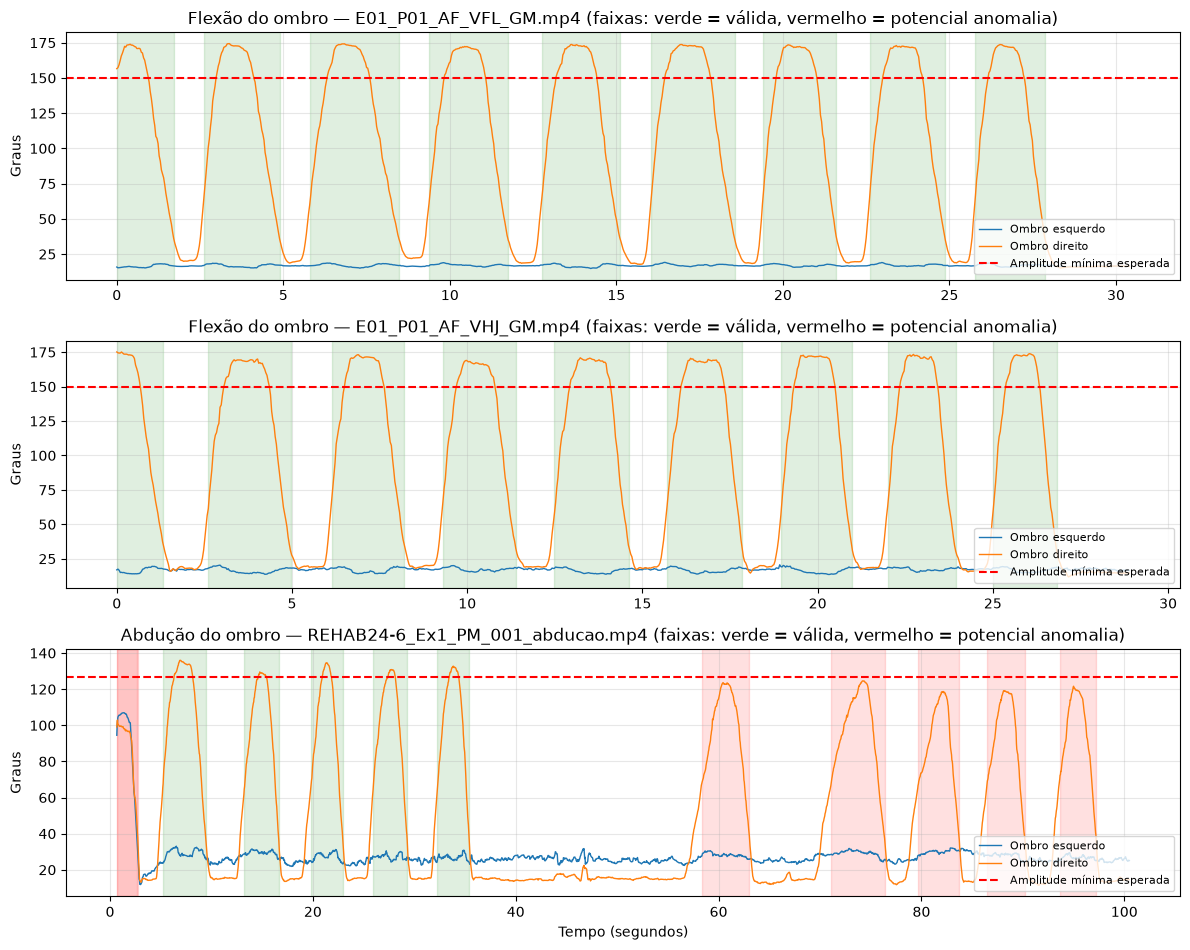

In [7]:
fig, axes = plt.subplots(len(execucoes), 1, figsize=(12, 3.2 * len(execucoes)), sharex=False)
axes = np.atleast_1d(axes)

for ax, (nome, (df_rep, df_hist, info)) in zip(axes, execucoes.items()):
    ax.plot(df_hist["tempo_segundos"], df_hist["angulo_esq"], label="Ombro esquerdo", linewidth=1)
    ax.plot(df_hist["tempo_segundos"], df_hist["angulo_dir"], label="Ombro direito", linewidth=1)
    ax.axhline(info["angulo_minimo"], color="red", linestyle="--", label="Amplitude mínima esperada")
    for _, rep in df_rep.iterrows():
        cor = "green" if rep["classificacao"] == "Valida" else "red"
        ax.axvspan(rep["inicio_segundos"], rep["fim_segundos"], color=cor, alpha=0.12)
    ax.set_title(f"{PERFIS_EXERCICIO[info['perfil']]['descricao']} — {nome} "
                 "(faixas: verde = válida, vermelho = potencial anomalia)")
    ax.set_ylabel("Graus")
    ax.grid(alpha=0.3)
    ax.legend(loc="lower right", fontsize=8)

axes[-1].set_xlabel("Tempo (segundos)")
plt.tight_layout()
plt.show()

#### Avaliação do detector contra os rótulos do fisioterapeuta

O vídeo do REHAB24-6 traz, para cada repetição, o intervalo de quadros e o rótulo de
correção atribuído pelo fisioterapeuta (`REHAB24-6_Segmentation.csv`). Cada repetição rotulada é
associada às repetições detectadas que se sobrepõem a ela no tempo; a repetição é considerada
**sinalizada** quando alguma detecção sobreposta foi classificada como *Potencial anomalia*.

Movimentos detectados fora de qualquer repetição rotulada são listados como *fora do protocolo*.

In [8]:
import re

df_avaliacao = pd.DataFrame()

if VIDEO_PATH_3 and ROTULOS_PATH_3:
    nome_erros = os.path.basename(VIDEO_PATH_3)
    df_rep_erros, _, info_erros = execucoes[nome_erros]
    id_video = re.search(r"PM_\d+", nome_erros).group(0)

    rotulos = pd.read_csv(ROTULOS_PATH_3, sep=";")
    rotulos = rotulos[rotulos["video_id"] == id_video].copy()
    rotulos["inicio_segundos"] = rotulos["first_frame"] / info_erros["fps"]
    rotulos["fim_segundos"] = rotulos["last_frame"] / info_erros["fps"]

    def sobreposicao(a_ini, a_fim, b_ini, b_fim):
        return max(0.0, min(a_fim, b_fim) - max(a_ini, b_ini))

    linhas, usadas = [], set()
    for _, r in rotulos.iterrows():
        sobrepostas = [
            (i, d) for i, d in df_rep_erros.iterrows()
            if sobreposicao(r["inicio_segundos"], r["fim_segundos"],
                            d["inicio_segundos"], d["fim_segundos"]) > 0
        ]
        usadas.update(i for i, _ in sobrepostas)
        sinalizada = any(d["classificacao"] != "Valida" for _, d in sobrepostas)
        linhas.append({
            "repeticao": int(r["repetition_number"]),
            "inicio_segundos": round(r["inicio_segundos"], 1),
            "fim_segundos": round(r["fim_segundos"], 1),
            "rotulo_fisioterapeuta": "Correta" if r["correctness"] == 1 else "Incorreta",
            "angulo_max_graus": max((d["angulo_max_graus"] for _, d in sobrepostas), default=None),
            "detectada": bool(sobrepostas),
            "sistema": "Potencial anomalia" if sinalizada else ("Valida" if sobrepostas else "-"),
        })
    df_avaliacao = pd.DataFrame(linhas)

    incorreta = df_avaliacao["rotulo_fisioterapeuta"] == "Incorreta"
    sinal = df_avaliacao["sistema"] == "Potencial anomalia"
    vp, fp = int((incorreta & sinal).sum()), int((~incorreta & sinal).sum())
    fn, vn = int((incorreta & ~sinal).sum()), int((~incorreta & ~sinal).sum())
    precisao = vp / (vp + fp) if vp + fp else 0.0
    revocacao = vp / (vp + fn) if vp + fn else 0.0
    acuracia = (vp + vn) / len(df_avaliacao) if len(df_avaliacao) else 0.0

    fora_protocolo = df_rep_erros.drop(index=list(usadas))

    print("=" * 50)
    print(f"AVALIAÇÃO CONTRA RÓTULOS — {nome_erros}")
    print("=" * 50)
    display(df_avaliacao)
    print(f"Repetições rotuladas detectadas: {int(df_avaliacao['detectada'].sum())}/{len(df_avaliacao)}")
    print(f"Matriz de confusão (positivo = execução incorreta): VP={vp} FP={fp} FN={fn} VN={vn}")
    print(f"Precisão: {precisao:.0%} | Revocação: {revocacao:.0%} | Acurácia: {acuracia:.0%}")
    if len(fora_protocolo):
        print(f"\nMovimentos fora do protocolo rotulado: {len(fora_protocolo)}")
        display(fora_protocolo)

    resultado_avaliacao_video = {
        "video": nome_erros, "vp": vp, "fp": fp, "fn": fn, "vn": vn,
        "precisao": round(precisao, 3), "revocacao": round(revocacao, 3), "acuracia": round(acuracia, 3),
    }
else:
    resultado_avaliacao_video = {}
    print("Vídeo ou rótulos do REHAB24-6 não encontrados: avaliação ignorada.")

AVALIAÇÃO CONTRA RÓTULOS — REHAB24-6_Ex1_PM_001_abducao.mp4


,repeticao,inicio_segundos,fim_segundos,rotulo_fisioterapeuta,angulo_max_graus,detectada,sistema
0,1,4.3,10.8,Correta,136.0,True,Valida
1,2,10.8,17.9,Correta,129.5,True,Valida
2,3,17.9,24.4,Correta,134.6,True,Valida
3,4,24.4,30.6,Correta,130.9,True,Valida
4,5,30.7,36.3,Correta,132.8,True,Valida
5,6,56.3,64.7,Incorreta,123.6,True,Potencial anomalia
6,7,68.7,78.2,Incorreta,124.6,True,Potencial anomalia
7,8,78.2,85.1,Incorreta,118.7,True,Potencial anomalia
8,9,85.2,91.5,Incorreta,119.2,True,Potencial anomalia
9,10,91.6,98.7,Incorreta,121.6,True,Potencial anomalia


Repetições rotuladas detectadas: 10/10
Matriz de confusão (positivo = execução incorreta): VP=5 FP=0 FN=0 VN=5
Precisão: 100% | Revocação: 100% | Acurácia: 100%

Movimentos fora do protocolo rotulado: 2


,braco,inicio_segundos,fim_segundos,duracao_segundos,angulo_max_graus,classificacao
0,esquerdo,0.67,2.70,2.03,107.0,Potencial anomalia
1,direito,0.67,2.77,2.10,102.9,Potencial anomalia


### 2.4 Padrões de movimentação do paciente

A partir das posições dos punhos registradas quadro a quadro (vídeo principal), calcula-se a
intensidade de movimento por segundo. Um **Isolation Forest** combinado a um escore-z identifica
segundos com padrão atípico, classificados como **agitação** (movimento acima do usual) ou
**imobilidade** (movimento abaixo do usual). A análise considera apenas a janela do exercício
(da primeira à última repetição): o repouso antes do início e depois do término não é anomalia.
Segundos com poucos quadros detectados também são descartados para evitar falsos positivos.

In [9]:
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest

df_frames = execucoes[os.path.basename(VIDEO_PATH)][1].copy()
fps_principal = execucoes[os.path.basename(VIDEO_PATH)][2]["fps"]

if df_frames.empty:
    raise ValueError("Nenhum ponto corporal registrado. Execute a seção 2.3 primeiro.")

# Deslocamento dos punhos entre frames consecutivos (coordenadas normalizadas)
for lado in ["esq", "dir"]:
    dx = df_frames[f"punho_{lado}_x"].diff()
    dy = df_frames[f"punho_{lado}_y"].diff()
    df_frames[f"desloc_{lado}"] = np.sqrt(dx**2 + dy**2)

df_frames["deslocamento"] = df_frames[["desloc_esq", "desloc_dir"]].mean(axis=1)
df_frames["segundo"] = df_frames["tempo_segundos"].astype(int)

# Agregação por segundo
df_movimentacao = (
    df_frames.groupby("segundo")
    .agg(
        intensidade=("deslocamento", "mean"),
        amplitude_punhos=("punho_esq_y", lambda s: s.max() - s.min()),
        frames_detectados=("frame", "count"),
    )
    .reset_index()
    .fillna(0)
)

# Descarta segundos incompletos (ex.: último segundo do vídeo)
df_movimentacao = df_movimentacao[
    df_movimentacao["frames_detectados"] >= 0.5 * fps_principal
]

# Considera apenas a janela do exercício (da 1ª à última repetição + 1 s):
# o repouso antes do início e depois do fim não é anomalia de movimentação
reps_principal = execucoes[os.path.basename(VIDEO_PATH)][0]
if len(reps_principal):
    inicio_exercicio = int(reps_principal["inicio_segundos"].min())
    fim_exercicio = reps_principal["fim_segundos"].max() + 1
    df_movimentacao = df_movimentacao[
        (df_movimentacao["segundo"] >= inicio_exercicio)
        & (df_movimentacao["segundo"] + 1 <= fim_exercicio)
    ]
df_movimentacao = df_movimentacao.reset_index(drop=True)

# Detector não supervisionado
X_mov = df_movimentacao[["intensidade", "amplitude_punhos"]].values
iso_mov = IsolationForest(n_estimators=200, contamination=0.08, random_state=42)
df_movimentacao["anomalia_iforest"] = iso_mov.fit_predict(X_mov) == -1

# Escore-z da intensidade
media = df_movimentacao["intensidade"].mean()
desvio = df_movimentacao["intensidade"].std() or 1e-9
df_movimentacao["zscore"] = (df_movimentacao["intensidade"] - media) / desvio
df_movimentacao["anomalia_zscore"] = df_movimentacao["zscore"].abs() > 2.0

df_movimentacao["anomalia"] = df_movimentacao["anomalia_iforest"] & df_movimentacao["anomalia_zscore"]
df_movimentacao["tipo"] = np.where(
    ~df_movimentacao["anomalia"], "normal",
    np.where(df_movimentacao["zscore"] > 0, "agitação", "imobilidade")
)

segundos_anomalos = df_movimentacao[df_movimentacao["anomalia"]]

print("=" * 50)
print("PADRÕES DE MOVIMENTAÇÃO")
print("=" * 50)
print(f"Duração analisada            : {len(df_movimentacao)} s")
print(f"Intensidade média            : {media:.4f}")
print(f"Segundos com padrão anômalo  : {len(segundos_anomalos)}")
print(f"  - agitação                 : {(segundos_anomalos['tipo'] == 'agitação').sum()}")
print(f"  - imobilidade              : {(segundos_anomalos['tipo'] == 'imobilidade').sum()}")
display(segundos_anomalos[["segundo", "intensidade", "zscore", "tipo"]].round(4))

PADRÕES DE MOVIMENTAÇÃO
Duração analisada            : 28 s
Intensidade média            : 0.0086
Segundos com padrão anômalo  : 0
  - agitação                 : 0
  - imobilidade              : 0


,segundo,intensidade,zscore,tipo


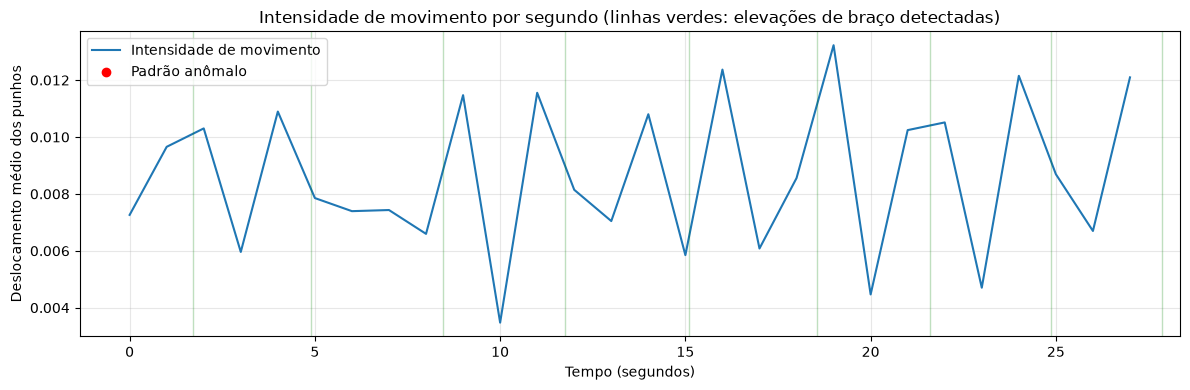

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df_movimentacao["segundo"], df_movimentacao["intensidade"], label="Intensidade de movimento")
ax.scatter(
    segundos_anomalos["segundo"], segundos_anomalos["intensidade"],
    color="red", zorder=3, label="Padrão anômalo"
)
for t in tempos_movimentos:  # repetições da seção 2.1
    ax.axvline(t, color="green", alpha=0.25, linewidth=1)

ax.set_title("Intensidade de movimento por segundo (linhas verdes: elevações de braço detectadas)")
ax.set_xlabel("Tempo (segundos)")
ax.set_ylabel("Deslocamento médio dos punhos")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 2.5 Detecção de objetos e áreas críticas com YOLOv8

O modelo **YOLOv8s** (pré-treinado no COCO) é aplicado a cada `PASSO_YOLO` quadros para
identificar pessoas e objetos da cena. A **maca** (classe `bench`/`bed`) é marcada como área
crítica. Usa-se a versão *small* porque a *nano* detecta a maca com confiança de apenas ~15 %.

A **área de exercício** é definida automaticamente pela posição do paciente no primeiro segundo,
expandida por uma margem de segurança. São sinalizados como eventos:

- **Paciente fora do enquadramento:** nenhuma pessoa detectada por mais de 1 s;
- **Saída da área de exercício:** centro do paciente fora da área definida;
- **Possível queda:** caixa do paciente mais larga que alta, ou altura reduzida a menos de 60 % da inicial;
- **Outra pessoa em cena:** mais de uma pessoa detectada (ex.: auxílio de terceiros).

É gerado um vídeo anotado (`video_yolo.mp4`) e um quadro de exemplo.

DETECÇÃO DE OBJETOS E ÁREAS CRÍTICAS (YOLOv8)
Quadros analisados       : 303
Quadros com paciente     : 303
Objetos detectados       : bench, remote
Maca (área crítica)      : detectada em 192/303 quadros, caixa (0, 836, 1080, 1267)
Área de exercício (px)   : (141, 0, 742, 1698)
Eventos identificados    : 0


,tipo,inicio_segundos,fim_segundos,gravidade


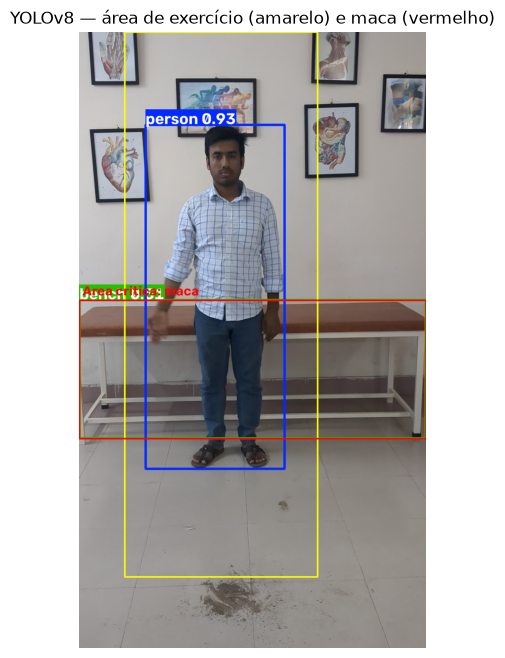

In [11]:
from ultralytics import YOLO

PASSO_YOLO = 3              # analisa 1 a cada N quadros
MARGEM_AREA = 0.25          # margem da área de exercício (proporção da caixa inicial)
CONFIANCA_PESSOA = 0.4
CONFIANCA_OBJETOS = 0.3     # objetos (ex.: maca) costumam ter confiança menor
CLASSES_MACA = {"bench", "bed"}

# yolov8s: o modelo nano (yolov8n) detecta a maca com confiança de apenas ~0,15
modelo_yolo = YOLO("yolov8s.pt")


def analisar_cena_yolo(caminho, salvar_video=None):
    cap = cv2.VideoCapture(caminho)
    fps_v = cap.get(cv2.CAP_PROP_FPS) or 30
    total_v = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    larg = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    alt = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    escritor = None
    if salvar_video:
        escritor = cv2.VideoWriter(salvar_video, cv2.VideoWriter_fourcc(*"mp4v"),
                                   fps_v / PASSO_YOLO, (larg, alt))

    registros, quadro_exemplo = [], None
    for idx in tqdm(range(total_v), desc=f"YOLOv8 — {os.path.basename(caminho)}"):
        ok, quadro = cap.read()
        if not ok:
            break
        if idx % PASSO_YOLO:
            continue
        res = modelo_yolo.predict(quadro, conf=CONFIANCA_OBJETOS, verbose=False,
                                  device=0 if GPU_DISPONIVEL else "cpu")[0]
        nomes = [res.names[int(c)] for c in res.boxes.cls.tolist()]
        confs = res.boxes.conf.tolist()
        caixas = res.boxes.xyxy.cpu().numpy()
        pessoas = [caixas[i] for i, n in enumerate(nomes)
                   if n == "person" and confs[i] >= CONFIANCA_PESSOA]
        principal = max(pessoas, key=lambda b: (b[2] - b[0]) * (b[3] - b[1])) if pessoas else None
        macas = [caixas[i] for i, n in enumerate(nomes) if n in CLASSES_MACA]
        registros.append({
            "frame": idx,
            "tempo_segundos": idx / fps_v,
            "pessoas": len(pessoas),
            "caixa": principal,
            "caixa_maca": macas[0] if macas else None,
            "objetos": sorted({n for n in nomes if n != "person"}),
        })
        anotado = res.plot()
        if escritor is not None:
            escritor.write(anotado)
        if quadro_exemplo is None and principal is not None and idx >= fps_v * 5:
            quadro_exemplo = anotado
    cap.release()
    if escritor is not None:
        escritor.release()
    df = pd.DataFrame(registros)
    df.attrs.update(largura=larg, altura=alt)
    return df, quadro_exemplo, fps_v


def eventos_da_cena(df_cena, fps_v):
    """Aplica as regras de área crítica, ausência, queda e terceiros."""
    com_pessoa = df_cena.dropna(subset=["caixa"])
    inicial = com_pessoa[com_pessoa["tempo_segundos"] <= com_pessoa["tempo_segundos"].min() + 1]
    caixa_ref = np.mean(np.stack(inicial["caixa"].values), axis=0)
    w_ref, h_ref = caixa_ref[2] - caixa_ref[0], caixa_ref[3] - caixa_ref[1]
    # Área de exercício limitada ao tamanho do quadro
    larg, alt = df_cena.attrs["largura"], df_cena.attrs["altura"]
    area = (max(0, caixa_ref[0] - MARGEM_AREA * w_ref), max(0, caixa_ref[1] - MARGEM_AREA * h_ref),
            min(larg, caixa_ref[2] + MARGEM_AREA * w_ref), min(alt, caixa_ref[3] + MARGEM_AREA * h_ref))

    flags = []
    for _, r in df_cena.iterrows():
        f = {"tempo_segundos": r["tempo_segundos"], "ausente": r["pessoas"] == 0,
             "terceiros": r["pessoas"] > 1, "fora_area": False, "possivel_queda": False}
        if r["caixa"] is not None:
            x1, y1, x2, y2 = r["caixa"]
            cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
            f["fora_area"] = not (area[0] <= cx <= area[2] and area[1] <= cy <= area[3])
            f["possivel_queda"] = (x2 - x1) > (y2 - y1) or (y2 - y1) < 0.6 * h_ref
        flags.append(f)
    df_flags = pd.DataFrame(flags)

    descricao = {
        "ausente": ("Paciente fora do enquadramento", "alta"),
        "fora_area": ("Saída da área de exercício", "media"),
        "possivel_queda": ("Possível queda", "alta"),
        "terceiros": ("Outra pessoa em cena", "baixa"),
    }
    duracao_min = {"ausente": 1.0, "fora_area": 0.5, "possivel_queda": 0.5, "terceiros": 0.5}
    passo_t = PASSO_YOLO / fps_v
    eventos = []
    for chave, (tipo, gravidade) in descricao.items():
        ativos = df_flags.loc[df_flags[chave], "tempo_segundos"].values
        if len(ativos) == 0:
            continue
        inicio = anterior = ativos[0]
        for t in list(ativos[1:]) + [None]:
            if t is None or t - anterior > 2 * passo_t:
                if anterior - inicio + passo_t >= duracao_min[chave]:
                    eventos.append({"tipo": tipo, "inicio_segundos": round(inicio, 2),
                                    "fim_segundos": round(anterior, 2), "gravidade": gravidade})
                if t is not None:
                    inicio = t
            if t is not None:
                anterior = t
    return pd.DataFrame(eventos, columns=["tipo", "inicio_segundos", "fim_segundos", "gravidade"]), area


df_cena, quadro_exemplo, fps_cena = analisar_cena_yolo(VIDEO_PATH, salvar_video="video_yolo.mp4")
df_eventos_yolo, area_exercicio = eventos_da_cena(df_cena, fps_cena)
objetos_cena = sorted({o for lista in df_cena["objetos"] for o in lista})
caixas_maca = df_cena["caixa_maca"].dropna()
area_maca = tuple(np.median(np.stack(caixas_maca.values), axis=0)) if len(caixas_maca) else None

print("=" * 50)
print("DETECÇÃO DE OBJETOS E ÁREAS CRÍTICAS (YOLOv8)")
print("=" * 50)
print(f"Quadros analisados       : {len(df_cena)}")
print(f"Quadros com paciente     : {int(df_cena['caixa'].notna().sum())}")
print(f"Objetos detectados       : {', '.join(objetos_cena) or 'nenhum'}")
print(f"Maca (área crítica)      : detectada em {len(caixas_maca)}/{len(df_cena)} quadros"
      + (f", caixa {tuple(int(v) for v in area_maca)}" if area_maca else ""))
print(f"Área de exercício (px)   : {tuple(int(v) for v in area_exercicio)}")
print(f"Eventos identificados    : {len(df_eventos_yolo)}")
display(df_eventos_yolo)

if quadro_exemplo is not None:
    x1, y1, x2, y2 = (int(v) for v in area_exercicio)
    cv2.rectangle(quadro_exemplo, (x1, y1), (x2, y2), (0, 255, 255), 4)
    if area_maca:
        m1, n1, m2, n2 = (int(v) for v in area_maca)
        cv2.rectangle(quadro_exemplo, (m1, n1), (m2, n2), (0, 0, 255), 4)
        cv2.putText(quadro_exemplo, "Area critica: maca", (m1 + 10, n1 - 15),
                    cv2.FONT_HERSHEY_SIMPLEX, 1.4, (0, 0, 255), 3)
    cv2.imwrite("yolo_quadro_exemplo.jpg", quadro_exemplo)
    plt.figure(figsize=(5, 8))
    plt.imshow(cv2.cvtColor(quadro_exemplo, cv2.COLOR_BGR2RGB))
    plt.title("YOLOv8 — área de exercício (amarelo) e maca (vermelho)")
    plt.axis("off")
    plt.show()

### 2.6 Relatório automático de desvios do procedimento

Consolida os desvios encontrados nas análises de vídeo (repetições, amplitude articular, ritmo,
padrões de movimentação e eventos de cena do YOLOv8) em uma tabela única e no arquivo
`relatorio_desvios_video.md`.

In [12]:
desvios = []
nome_principal = os.path.basename(VIDEO_PATH)

# Repetições (seção 2.2): amplitude pela regra cotovelo/olho e intervalo curto
for _, m in df_alertas_movimento.iterrows():
    desvios.append({"video": nome_principal, "origem": "repetições", "tipo": m["status"],
                    "momento_segundos": m["tempo_segundos"], "gravidade": "media"})

# Amplitude articular e ritmo (seção 2.3)
for nome, (df_rep, _, info) in execucoes.items():
    limiar = info["angulo_minimo"]
    for _, rep in df_rep[df_rep["angulo_max_graus"] < limiar].iterrows():
        desvios.append({"video": nome, "origem": "amplitude articular",
                        "tipo": f"Amplitude incompleta ({rep['angulo_max_graus']}° < {limiar}°)",
                        "momento_segundos": rep["fim_segundos"], "gravidade": "media"})
resumo_por_video = df_comparacao.set_index("video")
for nome, linha in resumo_por_video.iterrows():
    if linha["ritmo_irregular"]:
        desvios.append({"video": nome, "origem": "ritmo",
                        "tipo": f"Ritmo irregular (CV={linha['cv_ritmo']})",
                        "momento_segundos": None, "gravidade": "baixa"})

# Padrões de movimentação (seção 2.4)
for _, s in segundos_anomalos.iterrows():
    desvios.append({"video": nome_principal, "origem": "movimentação",
                    "tipo": f"Padrão de {s['tipo']}", "momento_segundos": s["segundo"],
                    "gravidade": "baixa"})

# Eventos de cena (seção 2.5)
for _, ev in df_eventos_yolo.iterrows():
    desvios.append({"video": nome_principal, "origem": "YOLOv8", "tipo": ev["tipo"],
                    "momento_segundos": ev["inicio_segundos"], "gravidade": ev["gravidade"]})

df_desvios = pd.DataFrame(desvios, columns=["video", "origem", "tipo", "momento_segundos", "gravidade"])

linhas = ["# Relatório de desvios do procedimento (vídeo)", ""]
for nome, linha in resumo_por_video.iterrows():
    linhas += [
        f"## {nome}",
        f"- Repetições: {linha['repeticoes']} (válidas: {linha['validas']})",
        f"- Ângulo máximo médio do ombro: {linha['angulo_max_medio']}° (mínimo: {linha['angulo_max_minimo']}°)",
        f"- Intervalo médio entre repetições: {linha['intervalo_medio_segundos']} s (CV {linha['cv_ritmo']})",
        "",
    ]
linhas += ["## Desvios identificados", ""]
if df_desvios.empty:
    linhas.append("Nenhum desvio identificado: execução dentro dos limites experimentais.")
else:
    for _, d in df_desvios.iterrows():
        momento = f" em {d['momento_segundos']} s" if pd.notna(d["momento_segundos"]) else ""
        linhas.append(f"- [{d['gravidade']}] {d['video']} — {d['origem']}: {d['tipo']}{momento}")

with open("relatorio_desvios_video.md", "w", encoding="utf-8") as f:
    f.write("\n".join(linhas))

print("=" * 50)
print("DESVIOS DO PROCEDIMENTO")
print("=" * 50)
print(f"Total de desvios: {len(df_desvios)}")
display(df_desvios)
print("Relatório salvo em relatorio_desvios_video.md")

DESVIOS DO PROCEDIMENTO
Total de desvios: 8


,video,origem,tipo,momento_segundos,gravidade
0,REHAB24-6_Ex1_PM_001_abducao.mp4,amplitude articular,Amplitude incompleta (107.0° < 127°),2.70,media
1,REHAB24-6_Ex1_PM_001_abducao.mp4,amplitude articular,Amplitude incompleta (102.9° < 127°),2.77,media
2,REHAB24-6_Ex1_PM_001_abducao.mp4,amplitude articular,Amplitude incompleta (123.6° < 127°),63.03,media
3,REHAB24-6_Ex1_PM_001_abducao.mp4,amplitude articular,Amplitude incompleta (124.6° < 127°),76.37,media
4,REHAB24-6_Ex1_PM_001_abducao.mp4,amplitude articular,Amplitude incompleta (118.7° < 127°),83.73,media
5,REHAB24-6_Ex1_PM_001_abducao.mp4,amplitude articular,Amplitude incompleta (119.2° < 127°),90.17,media
6,REHAB24-6_Ex1_PM_001_abducao.mp4,amplitude articular,Amplitude incompleta (121.6° < 127°),97.23,media
7,REHAB24-6_Ex1_PM_001_abducao.mp4,ritmo,Ritmo irregular (CV=0.812),NaN,baixa


Relatório salvo em relatorio_desvios_video.md


## 3. Processamento de Áudio

O módulo de processamento de áudio tem como objetivo transformar informações faladas em dados textuais que possam ser analisados pelo sistema de monitoramento.

O processamento será realizado em duas etapas:

1. Transcrição do conteúdo falado utilizando o modelo Whisper.
2. Análise do texto transcrito para identificar possíveis situações de atenção ou risco.

### 3.1 Transcrição de áudio com Whisper

O Whisper é um modelo de reconhecimento automático de fala capaz de converter áudio em texto.

A transcrição será utilizada como entrada para a análise de linguagem natural, permitindo identificar relatos de sintomas, pedidos de ajuda e outras informações relevantes para o monitoramento.

A transcrição é feita localmente com Whisper e, em paralelo, com o serviço gerenciado Azure Speech to Text (seção 3.5), permitindo comparar a qualidade das duas abordagens.

In [13]:
import os
import re
import json
import unicodedata
import asyncio

import torch
import whisper
import edge_tts
import librosa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pydub import AudioSegment
from IPython.display import Audio, display
try:
    from google.colab import files
except ImportError:
    files = None  # execução fora do Colab
from pysentimiento import create_analyzer

#### Roteiro sintético (usado apenas com `MODO_AUDIO = "sintetico"`)

Para demonstrar o funcionamento do processamento de áudio, será utilizado um diálogo fictício entre um médico e um paciente.

O diálogo será convertido em áudio por meio de vozes sintéticas em português brasileiro, utilizando a biblioteca Edge-TTS.

Serão gerados dois arquivos de áudio: um contendo a consulta completa, com as falas do médico e do paciente, e outro contendo exclusivamente as respostas do paciente.

Essa separação permitirá realizar a transcrição completa da consulta e, posteriormente, concentrar as análises nos relatos do paciente.

### 3.2 Origem do áudio da consulta

Dois modos são suportados pela variável `MODO_AUDIO`:

- **`"consulta_real"`** (padrão): áudio de uma consulta simulada real — *"Exemplo de uma estação de
  OSCE com foco na anamnese e comunicação"* (CDDE – FMRP-USP, YouTube `-BsAJyoj_Kw`), utilizado
  exclusivamente para fins acadêmicos. O arquivo `consulta_osce_fmrp.m4a` é procurado nas mesmas
  pastas dos vídeos (`/content`, Google Drive, `PASTA_VIDEOS`); se não for encontrado, tenta-se o
  download da faixa de áudio com `yt-dlp`.
- **`"sintetico"`**: diálogo fictício entre médico e paciente convertido em voz com Edge-TTS
  (células seguintes), útil quando não há gravação disponível.

No modo real, médico e paciente falam no mesmo arquivo; a separação é feita na seção 3.3.

In [14]:
import subprocess

MODO_AUDIO = "consulta_real"          # "consulta_real" ou "sintetico"
NOME_AUDIO_CONSULTA = "consulta_osce_fmrp.m4a"
URL_AUDIO_CONSULTA = "https://www.youtube.com/watch?v=-BsAJyoj_Kw"

if MODO_AUDIO == "consulta_real":
    arquivo_audio = localizar_video(NOME_AUDIO_CONSULTA)

    if arquivo_audio is None:
        print("Áudio da consulta não encontrado localmente. Tentando download com yt-dlp...")
        try:
            subprocess.run(
                [sys.executable, "-m", "yt_dlp", "-q", "--no-warnings",
                 "-f", "ba[language=pt-BR][ext=m4a]/ba[ext=m4a]",
                 "-o", NOME_AUDIO_CONSULTA, URL_AUDIO_CONSULTA],
                check=True,
            )
            arquivo_audio = os.path.abspath(NOME_AUDIO_CONSULTA)
        except Exception as erro:
            raise FileNotFoundError(
                f"Não foi possível obter {NOME_AUDIO_CONSULTA} ({erro}). Faça o upload do arquivo "
                "para /content ou para o Drive, ou use MODO_AUDIO = 'sintetico'."
            )
    print(f"Áudio da consulta real: {arquivo_audio}")
elif MODO_AUDIO == "sintetico":
    print("Modo sintético: o áudio será gerado a partir do roteiro nas próximas células.")
else:
    raise ValueError("MODO_AUDIO deve ser 'consulta_real' ou 'sintetico'.")

Áudio da consulta real: consulta_osce_fmrp.m4a


In [15]:
dialogo = [
    {
        "personagem": "medico",
        "texto": "Olá, bom dia! Como você está se sentindo hoje?"
    },
    {
        "personagem": "paciente",
        "texto": "Bom dia, doutor. Nos últimos três dias tenho sentido muita dor de cabeça e tontura."
    },
    {
        "personagem": "medico",
        "texto": "Você percebeu alguma dificuldade para respirar?"
    },
    {
        "personagem": "paciente",
        "texto": "Sim. Quando caminho, sinto um pouco de falta de ar e fico muito cansada."
    },
    {
        "personagem": "medico",
        "texto": "Como está a qualidade do seu sono?"
    },
    {
        "personagem": "paciente",
        "texto": "Tenho dormido mal e acordo várias vezes durante a noite."
    },
    {
        "personagem": "medico",
        "texto": "Você sente dor no peito ou percebe seu coração acelerado?"
    },
    {
        "personagem": "paciente",
        "texto": "Dor no peito não, mas às vezes sinto meu coração acelerar, principalmente quando faço esforço."
    },
    {
        "personagem": "medico",
        "texto": "Entendi. Obrigado pelas informações. Vamos continuar acompanhando seus sintomas."
    }
]

print("Roteiro criado!")
print("Quantidade de falas:", len(dialogo))

Roteiro criado!
Quantidade de falas: 9


In [16]:
voz_medico = "pt-BR-AntonioNeural"
voz_paciente = "pt-BR-FranciscaNeural"

async def gerar_consulta(dialogo):

    audio_completo = AudioSegment.empty()
    audio_paciente = AudioSegment.empty()

    arquivos_trechos = []

    for i, fala in enumerate(dialogo):

        if fala["personagem"] == "medico":
            voz = voz_medico
        else:
            voz = voz_paciente

        comunicador = edge_tts.Communicate(
            text=fala["texto"],
            voice=voz,
            rate="+0%"
        )

        arquivo_temporario = f"fala_{i}.mp3"

        await comunicador.save(arquivo_temporario)

        trecho = AudioSegment.from_mp3(arquivo_temporario)

        arquivos_trechos.append(arquivo_temporario)

        audio_completo += trecho
        audio_completo += AudioSegment.silent(duration=600)

        if fala["personagem"] == "paciente":
            audio_paciente += trecho
            audio_paciente += AudioSegment.silent(duration=600)

    audio_completo.export(
        "consulta_ficticia.mp3",
        format="mp3"
    )

    audio_paciente.export(
        "audio_paciente.mp3",
        format="mp3"
    )

    return "consulta_ficticia.mp3", "audio_paciente.mp3"


if MODO_AUDIO == "sintetico":
    arquivo_audio, arquivo_audio_paciente = await gerar_consulta(dialogo)

    print("Áudio completo:", arquivo_audio)
    print("Áudio do paciente:", arquivo_audio_paciente)
else:
    print("Modo consulta_real: roteiro sintético não utilizado.")

Modo consulta_real: roteiro sintético não utilizado.


In [17]:
display(Audio(arquivo_audio))

In [18]:
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"

print("Dispositivo utilizado:", dispositivo)

# "medium" transcreve melhor áudio real; em CPU, "small" é mais viável
WHISPER_MODELO = "medium" if dispositivo == "cuda" else "small"
print("Modelo Whisper:", WHISPER_MODELO)

modelo_whisper = whisper.load_model(
    WHISPER_MODELO,
    device=dispositivo
)

Dispositivo utilizado: cuda
Modelo Whisper: medium


In [19]:
resultado_whisper = modelo_whisper.transcribe(
    arquivo_audio,
    language="pt",
    task="transcribe",
    fp16=(dispositivo == "cuda")
)

transcricao = resultado_whisper["text"]

print("TRANSCRIÇÃO DA CONSULTA:")
print(transcricao)

TRANSCRIÇÃO DA CONSULTA:
 Bom, o senhor Carlos, o senhor está sentindo dor agora? Não, em momento não. E me conta como é a dor que o senhor já sentiu? Eu estava trabalhando na escritória e senti essa dor. Uma dor fraca, não dei muita importância. A segunda vez, quando estava caminhando no final da tarde, uma dor um pouco mais forte, em seguida eu diminui o ritmo da caminhada. E a terceira vez foi à noite, quando estava em casa, uns três dias atrás, uma dor mais fraca, mas já fiquei mais preocupado. Em que lugar do peito que a dor é mais forte? No meio do peito. E a dor espalha para algum lugar? Às vezes eu sinto que ela vem até o pescoço. Junto com a dor, o senhor sente algum outro problema? Tipo falta de ar, um jôo, batedeira no peito? Não, não, só na segunda vez que a dor foi mais forte, eu senti um estômago em panzinado, somente essa vez. E o senhor tem boa direção? Tem. O intestino funciona bem? Funciona bem. E o senhor usou algum remédio para além dessa dor? Não, alguns minutos ap

### 3.3 Separação entre médico e paciente

Para concentrar a análise nos relatos do paciente, as falas são atribuídas a cada locutor:

- **Com Azure configurado:** o **Azure Speech — ConversationTranscriber** faz a *diarização*
  (identifica quem fala em cada trecho). O médico é o locutor com maior proporção de perguntas;
  o paciente é o locutor com mais palavras entre os demais.
- **Sem Azure:** heurística sobre os segmentos do Whisper — segmentos terminados em "?" são
  atribuídos ao médico e os demais ao paciente (aproximação, documentada como limitação).

Os trechos do paciente são recortados e concatenados em `audio_paciente.wav`, utilizado nas
análises acústicas e de texto seguintes. No modo sintético, os arquivos já são gerados separados.

In [20]:
import threading
from pydub import AudioSegment


def diarizar_azure(caminho_wav):
    """Transcrição com identificação de locutores (Azure ConversationTranscriber)."""
    import azure.cognitiveservices.speech as speechsdk

    cfg = speechsdk.SpeechConfig(
        subscription=obter_segredo("AZURE_SPEECH_KEY"),
        region=obter_segredo("AZURE_SPEECH_REGION"),
    )
    cfg.speech_recognition_language = "pt-BR"
    transcritor = speechsdk.transcription.ConversationTranscriber(
        speech_config=cfg, audio_config=speechsdk.audio.AudioConfig(filename=caminho_wav)
    )
    falas, fim, erros = [], threading.Event(), []

    def _transcrito(evt):
        r = evt.result
        if r.reason == speechsdk.ResultReason.RecognizedSpeech and r.text.strip():
            falas.append({
                "inicio": r.offset / 1e7,                 # offsets em unidades de 100 ns
                "fim": (r.offset + r.duration) / 1e7,
                "locutor": r.speaker_id,
                "texto": r.text.strip(),
            })

    def _cancelado(evt):
        if evt.reason == speechsdk.CancellationReason.Error:
            erros.append(evt.error_details)
        fim.set()

    transcritor.transcribed.connect(_transcrito)
    transcritor.session_stopped.connect(lambda evt: fim.set())
    transcritor.canceled.connect(_cancelado)
    transcritor.start_transcribing_async().get()
    fim.wait(timeout=900)
    transcritor.stop_transcribing_async().get()
    if erros:
        raise RuntimeError(erros[0])
    return falas


def identificar_paciente(df):
    """Médico: maior proporção de perguntas; paciente: mais palavras entre os demais."""
    estat = df.groupby("locutor").agg(
        falas=("texto", "count"),
        perguntas=("texto", lambda s: s.str.contains(r"\?").sum()),
        palavras=("texto", lambda s: s.str.split().str.len().sum()),
    )
    estat["taxa_perguntas"] = estat["perguntas"] / estat["falas"]
    medico = estat["taxa_perguntas"].idxmax()
    restantes = estat.drop(index=medico)
    paciente = restantes["palavras"].idxmax() if len(restantes) else None
    return medico, paciente, estat


if MODO_AUDIO == "sintetico":
    falas_paciente = [f["texto"] for f in dialogo if f["personagem"] == "paciente"]
    metodo_separacao = "roteiro (áudios gerados separadamente)"
    df_locutores = pd.DataFrame()
else:
    wav_consulta = "consulta_16k.wav"
    audio_consulta = AudioSegment.from_file(arquivo_audio).set_frame_rate(16000).set_channels(1)
    audio_consulta.export(wav_consulta, format="wav")

    falas = []
    if AZURE_CONFIGURADO:
        try:
            falas = diarizar_azure(wav_consulta)
            metodo_separacao = "Azure ConversationTranscriber (diarização)"
        except Exception as erro:
            print(f"Falha na diarização Azure ({erro}). Usando heurística sobre o Whisper.")

    if falas:
        df_locutores = pd.DataFrame(falas)
        medico, paciente, estat_locutores = identificar_paciente(df_locutores)
        df_locutores["papel"] = df_locutores["locutor"].map(
            lambda l: "médico" if l == medico else ("paciente" if l == paciente else "outro")
        )
        display(estat_locutores)
    else:
        metodo_separacao = "heurística sobre segmentos do Whisper"
        df_locutores = pd.DataFrame([
            {"inicio": s["start"], "fim": s["end"], "locutor": "-", "texto": s["text"].strip(),
             "papel": "médico" if s["text"].strip().endswith("?") else "paciente"}
            for s in resultado_whisper["segments"] if s["text"].strip()
        ])

    trechos_paciente = df_locutores[df_locutores["papel"] == "paciente"]
    audio_paciente_seg = AudioSegment.empty()
    for _, fala in trechos_paciente.iterrows():
        audio_paciente_seg += audio_consulta[int(fala["inicio"] * 1000):int(fala["fim"] * 1000)]
        audio_paciente_seg += AudioSegment.silent(duration=300)
    arquivo_audio_paciente = "audio_paciente.wav"
    audio_paciente_seg.export(arquivo_audio_paciente, format="wav")
    falas_paciente = trechos_paciente["texto"].tolist()

    print(f"Método de separação: {metodo_separacao}")
    print(f"Falas do médico: {(df_locutores['papel'] == 'médico').sum()} | "
          f"falas do paciente: {len(trechos_paciente)} | "
          f"áudio do paciente: {len(audio_paciente_seg) / 1000:.1f} s")
    display(df_locutores[["inicio", "fim", "papel", "texto"]].round(1))

Método de separação: heurística sobre segmentos do Whisper
Falas do médico: 15 | falas do paciente: 27 | áudio do paciente: 102.1 s


,inicio,fim,papel,texto
0,30.0,34.0,médico,"Bom, o senhor Carlos, o senhor está sentindo d..."
1,34.0,36.0,paciente,"Não, em momento não."
2,36.0,39.0,médico,E me conta como é a dor que o senhor já sentiu?
3,39.0,43.0,paciente,Eu estava trabalhando na escritória e senti es...
4,43.0,46.0,paciente,"Uma dor fraca, não dei muita importância."
5,46.0,50.0,paciente,"A segunda vez, quando estava caminhando no fin..."
6,50.0,55.0,paciente,"uma dor um pouco mais forte, em seguida eu dim..."
7,55.0,59.0,paciente,"E a terceira vez foi à noite, quando estava em..."
8,59.0,63.0,paciente,"uma dor mais fraca, mas já fiquei mais preocup..."
9,63.0,67.0,médico,Em que lugar do peito que a dor é mais forte?


In [21]:
display(Audio(arquivo_audio_paciente))

In [22]:
resultado_whisper_paciente = modelo_whisper.transcribe(
    arquivo_audio_paciente,
    language="pt",
    task="transcribe",
    fp16=(dispositivo == "cuda")
)

transcricao_paciente = resultado_whisper_paciente["text"]

print("TRANSCRIÇÃO DO PACIENTE:")
print(transcricao_paciente)

TRANSCRIÇÃO DO PACIENTE:
 No momento não. Eu estava trabalhando na escritória e sentia essa dor. Uma dor fraca, não dei muita importância. A segunda vez, quando estava caminhando no final da tarde, uma dor um pouco mais forte. Em seguida eu diminui o ritmo da caminhada. E a terceira vez foi à noite, quando estava em casa, uns três dias atrás, uma dor mais fraca, mas já fiquei mais preocupado. Eu senti que a dor estava no meio do peito. Eu senti que ela vinha até o pescoço. Não, só na segunda vez, que a dor foi mais forte, eu senti um estômago meio panzinal. Somente essa vez. Tem o intestino. Isso é o caso? O senhor usa o estômago? Não, alguns minutos após, ela passou sozinha. O quarto? Não, ninguém da minha família. Só o meu pai, que ele pertence. Eu fumei, dos meus 14, uma meia, duas, uma e meia. Somente a sua semana, cerveja. Física? Não, eu só, três a quatro vezes por semana, faço caminhada. Não é um prático nervoso, ansioso. Não, não me constata. Apenas os problemas no escritório, 

In [23]:
def normalizar_texto(texto):

    texto = texto.lower()

    texto = unicodedata.normalize(
        "NFD",
        texto
    )

    texto = "".join(
        caractere
        for caractere in texto
        if unicodedata.category(caractere) != "Mn"
    )

    return texto

In [24]:
# --------------------------------------------------
# Identificação contextual de sintomas
# Diferencia menções positivas de sintomas negados.
# --------------------------------------------------

termos_criticos_contexto = {
    "dor de cabeca": {
        "descricao": "Possível relato de cefaleia",
        "variacoes": [r"dor de cabeca", r"dores de cabeca"]
    },
    "tontura": {
        "descricao": "Possível relato de tontura",
        "variacoes": [r"tontura", r"tonturas", r"estou tonto", r"estou tonta"]
    },
    "falta de ar": {
        "descricao": "Possível relato de dificuldade respiratória",
        "variacoes": [r"falta de ar", r"sem ar"]
    },
    "cansaço": {
        "descricao": "Possível relato de cansaço",
        "variacoes": [r"cansad[oa]s?", r"cansaco", r"fadiga"]
    },
    "dor no peito": {
        "descricao": "Possível relato de dor torácica",
        "variacoes": [r"dor(es)? no peito", r"dor toracica", r"meio do peito"]
    },
    "palpitação": {
        "descricao": "Possível relato de palpitações",
        "variacoes": [r"coracao acelerado", r"coracao acelerar", r"palpitacoes"]
    },
    "alteração do sono": {
        "descricao": "Possível alteração do sono",
        "variacoes": [r"dormindo mal", r"durmo mal", r"sono ruim", r"acordo varias vezes"]
    },
    "dificuldade para respirar": {
        "descricao": "Possível dificuldade respiratória",
        "variacoes": [r"dificuldade para respirar", r"dificuldade de respirar", r"respirar com dificuldade"]
    },
    # Termos acrescentados para a consulta real (dor torácica / fatores de risco)
    "sintoma aos esforços": {
        "descricao": "Sintoma desencadeado por esforço",
        "variacoes": [r"esforco", r"caminhando", r"caminhada", r"subir escada"]
    },
    "irradiação da dor": {
        "descricao": "Possível irradiação da dor",
        "variacoes": [r"(vem|vai|espalha|irradia)\w* ate o", r"pescoco", r"braco esquerdo", r"mandibula"]
    },
    "desconforto abdominal": {
        "descricao": "Possível desconforto epigástrico",
        "variacoes": [r"estomago", r"estufad\w*", r"empanzinad\w*", r"azia"]
    },
    "tabagismo": {
        "descricao": "Fator de risco: tabagismo (atual ou prévio)",
        "variacoes": [r"\bfumei\b", r"\bfumo\b", r"fumante", r"cigarros?"]
    },
    "histórico familiar cardíaco": {
        "descricao": "Fator de risco: histórico familiar cardíaco",
        "variacoes": [r"infarto", r"problema (do|no) coracao"]
    }
}

# Expressões comuns de negação em português.
expressoes_negacao = [
    r"\bnao\b", r"\bsem\b", r"\bnego\b", r"\bnega\b",
    r"\bnegou\b", r"\bnunca\b", r"\bjamais\b"
]

def identificar_sintomas(texto):
    texto_normalizado = normalizar_texto(texto)
    resultados = []
    encontrados = set()

    for nome, dados in termos_criticos_contexto.items():
        for variacao in dados["variacoes"]:
            for ocorrencia in re.finditer(variacao, texto_normalizado):
                inicio, fim = ocorrencia.span()

                # Analisa uma janela curta antes e depois do termo, limitada à
                # oração atual: a negação não atravessa ".", "!", "?", ";" nem " mas ".
                limite_oracao = max(
                    texto_normalizado.rfind(s, 0, inicio) + len(s)
                    if texto_normalizado.rfind(s, 0, inicio) >= 0 else 0
                    for s in [".", "!", "?", ";", " mas "]
                )
                contexto_antes = texto_normalizado[max(limite_oracao, inicio - 45):inicio]
                contexto_depois = texto_normalizado[fim:min(len(texto_normalizado), fim + 25)]

                negacao_antes = any(
                    re.search(expressao, contexto_antes)
                    for expressao in expressoes_negacao
                )

                # Exemplos: "dor no peito não", "não sinto dor no peito".
                negacao_depois = bool(
                    re.search(r"^\s*(nao|nunca|jamais)\b", contexto_depois)
                )

                status = "Menção negada" if (negacao_antes or negacao_depois) else "Menção identificada"

                chave = (nome, status)
                if chave not in encontrados:
                    resultados.append({
                        "termo": nome,
                        "descricao": dados["descricao"],
                        "status": status,
                        "trecho_contextual": texto_normalizado[
                            max(0, inicio - 45):min(len(texto_normalizado), fim + 25)
                        ].strip()
                    })
                    encontrados.add(chave)

    return resultados

sintomas_encontrados = identificar_sintomas(transcricao_paciente)
df_sintomas = pd.DataFrame(sintomas_encontrados)

print("TERMOS CRÍTICOS COM ANÁLISE DE NEGAÇÃO:")
display(df_sintomas)

print(
    "\nAtenção: a identificação é baseada em regras textuais. "
    "Ela não confirma diagnóstico nem substitui avaliação profissional."
)

TERMOS CRÍTICOS COM ANÁLISE DE NEGAÇÃO:


,termo,descricao,status,trecho_contextual
0,dor no peito,Possível relato de dor torácica,Menção identificada,ais preocupado. eu senti que a dor estava no m...
1,sintoma aos esforços,Sintoma desencadeado por esforço,Menção identificada,"ta importancia. a segunda vez, quando estava c..."
2,irradiação da dor,Possível irradiação da dor,Menção identificada,meio do peito. eu senti que ela vinha ate o pe...
3,desconforto abdominal,Possível desconforto epigástrico,Menção identificada,"a vez, que a dor foi mais forte, eu senti um e..."
4,tabagismo,Fator de risco: tabagismo (atual ou prévio),Menção identificada,"familia. so o meu pai, que ele pertence. eu fu..."



Atenção: a identificação é baseada em regras textuais. Ela não confirma diagnóstico nem substitui avaliação profissional.


In [25]:
audio_paciente, sr = librosa.load(
    arquivo_audio_paciente,
    sr=16000,
    mono=True
)

duracao = librosa.get_duration(
    y=audio_paciente,
    sr=sr
)

print("Duração:", round(duracao, 2), "segundos")
print("Taxa de amostragem:", sr)

Duração: 102.06 segundos
Taxa de amostragem: 16000


In [26]:
def analisar_caracteristicas_vocais(audio, sr, texto):

    duracao = librosa.get_duration(
        y=audio,
        sr=sr
    )

    # Frequência fundamental
    pitch = librosa.yin(
        audio,
        fmin=65,
        fmax=400,
        sr=sr
    )

    pitch_mediano = np.median(pitch)
    pitch_desvio = np.std(pitch)

    # Energia vocal
    rms = librosa.feature.rms(
        y=audio
    )[0]

    energia_media = np.mean(rms)

    # Centroide espectral
    centroide = librosa.feature.spectral_centroid(
        y=audio,
        sr=sr
    )[0]

    centroide_medio = np.mean(centroide)

    # Taxa de cruzamento por zero
    zcr = librosa.feature.zero_crossing_rate(
        y=audio
    )[0]

    zcr_medio = np.mean(zcr)

    # Intervalos com atividade sonora
    intervalos = librosa.effects.split(
        audio,
        top_db=30
    )

    tempo_falado = sum(
        fim - inicio
        for inicio, fim in intervalos
    ) / sr

    proporcao_fala = (
        tempo_falado / duracao
        if duracao > 0 else 0
    )

    # Velocidade aproximada da fala
    quantidade_palavras = len(texto.split())

    taxa_fala = (
        quantidade_palavras / duracao * 60
        if duracao > 0 else 0
    )

    proporcao_pausas = max(
        0,
        1 - proporcao_fala
    )

    return {
        "duracao_segundos": round(float(duracao), 2),
        "pitch_mediano_hz": round(float(pitch_mediano), 2),
        "variacao_pitch_hz": round(float(pitch_desvio), 2),
        "energia_media": round(float(energia_media), 4),
        "centroide_espectral": round(float(centroide_medio), 2),
        "cruzamento_zero": round(float(zcr_medio), 4),
        "taxa_fala_palavras_min": round(float(taxa_fala), 2),
        "proporcao_fala": round(float(proporcao_fala), 3),
        "proporcao_pausas": round(float(proporcao_pausas), 3)
    }

In [27]:
caracteristicas_vocais = analisar_caracteristicas_vocais(
    audio_paciente,
    sr,
    transcricao_paciente
)

df_caracteristicas = pd.DataFrame(
    [caracteristicas_vocais]
)

display(df_caracteristicas)

,duracao_segundos,pitch_mediano_hz,variacao_pitch_hz,energia_media,centroide_espectral,cruzamento_zero,taxa_fala_palavras_min,proporcao_fala,proporcao_pausas
0,102.06,146.33,82.36,0.0327,1354.55,0.07,142.85,0.941,0.059


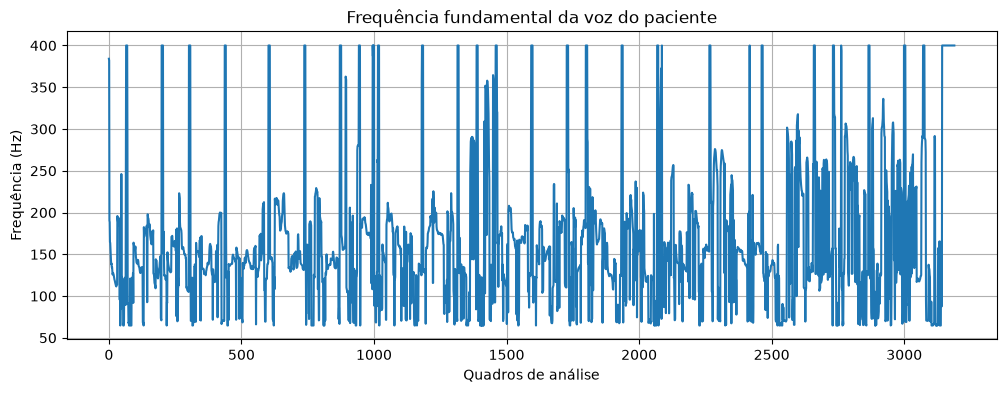

In [28]:
pitch = librosa.yin(
    audio_paciente,
    fmin=65,
    fmax=400,
    sr=sr
)

plt.figure(figsize=(12, 4))

plt.plot(pitch)

plt.title("Frequência fundamental da voz do paciente")
plt.xlabel("Quadros de análise")
plt.ylabel("Frequência (Hz)")
plt.grid(True)

plt.show()

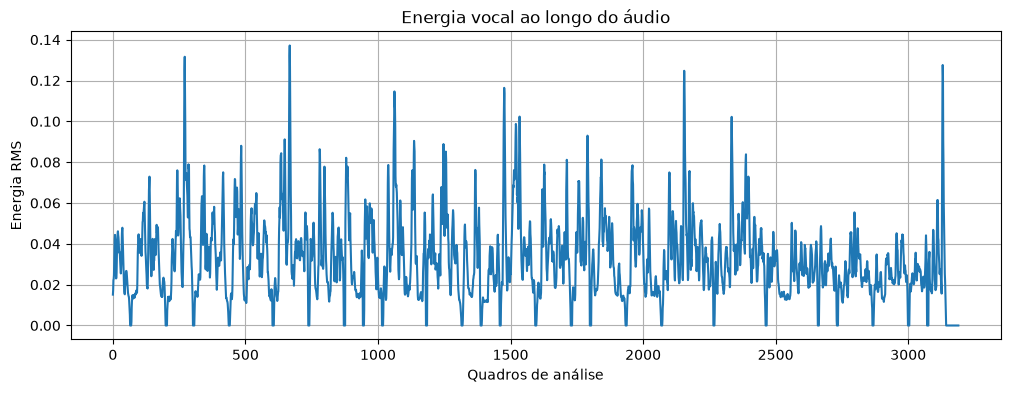

In [29]:
energia = librosa.feature.rms(
    y=audio_paciente
)[0]

plt.figure(figsize=(12, 4))

plt.plot(energia)

plt.title("Energia vocal ao longo do áudio")
plt.xlabel("Quadros de análise")
plt.ylabel("Energia RMS")
plt.grid(True)

plt.show()

### 3.4 Indicadores acústicos relacionados à fala e à respiração

Nesta etapa são consolidadas medidas acústicas que podem ser úteis para observar mudanças no padrão de fala, como velocidade, pausas, intensidade e variação da frequência fundamental.

As medidas são tratadas como **indicadores exploratórios**, não como detectores clínicos. Pausas podem ocorrer por diversos motivos, e características da voz dependem também do locutor, do microfone, do ambiente e da forma de gravação.

Como o áudio de demonstração foi sintetizado por TTS, os resultados descrevem a voz artificial gerada e **não permitem validar cansaço ou dificuldade respiratória de uma pessoa real**.

INDICADORES ACÚSTICOS EXPLORATÓRIOS:


,duracao_total_segundos,tempo_com_atividade_segundos,tempo_sem_atividade_segundos,proporcao_sem_atividade,quantidade_segmentos_sonoros,pausa_media_segundos,maior_pausa_segundos,velocidade_fala_palavras_min,pitch_mediano_hz,variacao_pitch_hz,energia_rms_media,variacao_energia_rms
0,102.06,96.0,6.06,0.059,26,0.18,0.22,142.85,146.33,82.36,0.0327,0.0199


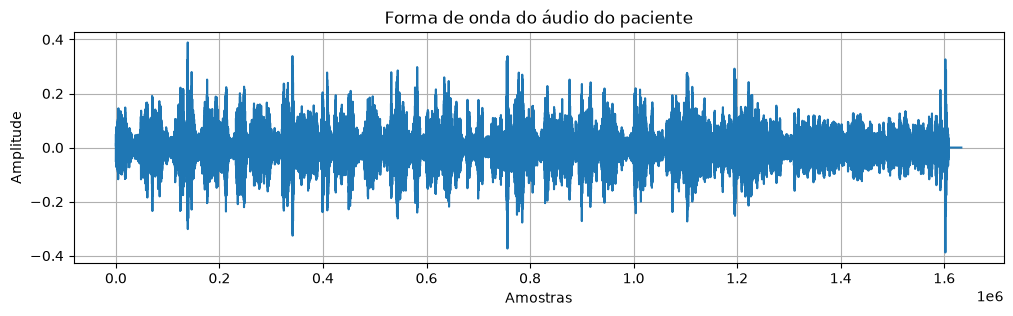

Interpretação: pausas, velocidade e variações de energia/pitch podem orientar uma revisão do áudio, mas não identificam isoladamente fadiga ou dificuldade respiratória.


In [30]:
# --------------------------------------------------
# Indicadores acústicos exploratórios
# --------------------------------------------------

def extrair_indicadores_acusticos(audio, sr, texto):
    duracao = librosa.get_duration(y=audio, sr=sr)

    # Segmentos com atividade sonora (estimativa simples de voz/atividade).
    intervalos = librosa.effects.split(audio, top_db=30)

    duracoes_segmentos = [
        (fim - inicio) / sr
        for inicio, fim in intervalos
    ]

    tempo_ativo = float(sum(duracoes_segmentos))
    tempo_sem_atividade = max(0.0, duracao - tempo_ativo)

    pausas_entre_segmentos = []
    for i in range(1, len(intervalos)):
        pausa = (intervalos[i][0] - intervalos[i - 1][1]) / sr
        if pausa > 0:
            pausas_entre_segmentos.append(float(pausa))

    palavras = len(texto.split())
    velocidade_fala = palavras / (duracao / 60) if duracao > 0 else 0

    # Pitch: considera apenas valores finitos.
    pitch = librosa.yin(audio, fmin=65, fmax=400, sr=sr)
    pitch = pitch[np.isfinite(pitch)]

    rms = librosa.feature.rms(y=audio)[0]
    energia_media = float(np.mean(rms)) if len(rms) else 0.0
    energia_desvio = float(np.std(rms)) if len(rms) else 0.0

    return {
        "duracao_total_segundos": round(float(duracao), 2),
        "tempo_com_atividade_segundos": round(tempo_ativo, 2),
        "tempo_sem_atividade_segundos": round(tempo_sem_atividade, 2),
        "proporcao_sem_atividade": round(
            tempo_sem_atividade / duracao, 3
        ) if duracao > 0 else 0,
        "quantidade_segmentos_sonoros": len(intervalos),
        "pausa_media_segundos": round(
            float(np.mean(pausas_entre_segmentos)), 2
        ) if pausas_entre_segmentos else 0,
        "maior_pausa_segundos": round(
            float(np.max(pausas_entre_segmentos)), 2
        ) if pausas_entre_segmentos else 0,
        "velocidade_fala_palavras_min": round(float(velocidade_fala), 2),
        "pitch_mediano_hz": round(float(np.median(pitch)), 2) if len(pitch) else None,
        "variacao_pitch_hz": round(float(np.std(pitch)), 2) if len(pitch) else None,
        "energia_rms_media": round(energia_media, 4),
        "variacao_energia_rms": round(energia_desvio, 4)
    }

indicadores_acusticos = extrair_indicadores_acusticos(
    audio_paciente,
    sr,
    transcricao_paciente
)

df_indicadores_acusticos = pd.DataFrame([indicadores_acusticos])

print("INDICADORES ACÚSTICOS EXPLORATÓRIOS:")
display(df_indicadores_acusticos)

# Visualização das pausas e da atividade sonora.
plt.figure(figsize=(12, 3))
plt.plot(audio_paciente)
plt.title("Forma de onda do áudio do paciente")
plt.xlabel("Amostras")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

print(
    "Interpretação: pausas, velocidade e variações de energia/pitch "
    "podem orientar uma revisão do áudio, mas não identificam isoladamente "
    "fadiga ou dificuldade respiratória."
)

In [31]:
analisador_sentimentos = create_analyzer(
    task="sentiment",
    lang="pt"
)

In [32]:
resultado_sentimento = analisador_sentimentos.predict(
    transcricao_paciente
)

print("SENTIMENTO IDENTIFICADO:")
print(resultado_sentimento.output)

print("\nPROBABILIDADES:")

for sentimento, probabilidade in resultado_sentimento.probas.items():

    print(
        sentimento,
        ":",
        round(probabilidade * 100, 2),
        "%"
    )

SENTIMENTO IDENTIFICADO:
NEG

PROBABILIDADES:
NEG : 79.79 %
NEU : 17.92 %
POS : 2.28 %


In [33]:
resultados_sentimentos = []

# falas_paciente vem da seção 3.3 (roteiro ou falas reais separadas)
for fala in falas_paciente:

    resultado = analisador_sentimentos.predict(
        fala
    )

    resultados_sentimentos.append({
        "fala": fala,
        "sentimento": resultado.output,
        "positivo": round(
            resultado.probas.get("POS", 0), 4
        ),
        "negativo": round(
            resultado.probas.get("NEG", 0), 4
        ),
        "neutro": round(
            resultado.probas.get("NEU", 0), 4
        )
    })

df_sentimentos = pd.DataFrame(
    resultados_sentimentos
)

display(df_sentimentos)

,fala,sentimento,positivo,negativo,neutro
0,"Não, em momento não.",NEU,0.0921,0.1830,0.7249
1,Eu estava trabalhando na escritória e senti es...,NEU,0.0387,0.0290,0.9323
2,"Uma dor fraca, não dei muita importância.",NEU,0.0270,0.3637,0.6093
3,"A segunda vez, quando estava caminhando no fin...",NEU,0.0209,0.0284,0.9507
4,"uma dor um pouco mais forte, em seguida eu dim...",NEU,0.0136,0.3200,0.6664
5,"E a terceira vez foi à noite, quando estava em...",NEU,0.0127,0.0586,0.9288
6,"uma dor mais fraca, mas já fiquei mais preocup...",NEG,0.0131,0.8461,0.1408
7,No meio do peito.,NEU,0.0940,0.1926,0.7134
8,Às vezes eu sinto que ela vem até o pescoço.,NEU,0.0502,0.0969,0.8530
9,"Não, não, só na segunda vez que a dor foi mais...",NEU,0.0347,0.4774,0.4879


In [34]:
resultado_audio = {

    "arquivo": arquivo_audio,

    "arquivo_audio_paciente": arquivo_audio_paciente,

    "transcricao_completa": transcricao,

    "transcricao_paciente": transcricao_paciente,

    "sintomas_identificados": sintomas_encontrados,

    "caracteristicas_vocais": caracteristicas_vocais,

    "indicadores_acusticos": indicadores_acusticos,

    "sentimento_geral": {
        "classificacao": resultado_sentimento.output,
        "probabilidades": resultado_sentimento.probas
    },

    "sentimentos_por_fala": resultados_sentimentos
}

print("ANÁLISE MULTIMODAL DE ÁUDIO CONCLUÍDA!")

ANÁLISE MULTIMODAL DE ÁUDIO CONCLUÍDA!


In [35]:
resumo_audio = pd.DataFrame([{
    "Arquivo": resultado_audio["arquivo"],
    "Duração (segundos)": caracteristicas_vocais["duracao_segundos"],
    "Menções identificadas": sum(1 for x in sintomas_encontrados if x["status"] == "Menção identificada"),
    "Menções negadas": sum(1 for x in sintomas_encontrados if x["status"] == "Menção negada"),
    "Sentimento geral": resultado_sentimento.output,
    "Pitch mediano (Hz)": caracteristicas_vocais["pitch_mediano_hz"],
    "Energia média": caracteristicas_vocais["energia_media"],
    "Velocidade da fala (palavras/min)": indicadores_acusticos["velocidade_fala_palavras_min"],
    "Maior pausa (s)": indicadores_acusticos["maior_pausa_segundos"]
}])

display(resumo_audio)

,Arquivo,Duração (segundos),Menções identificadas,Menções negadas,Sentimento geral,Pitch mediano (Hz),Energia média,Velocidade da fala (palavras/min),Maior pausa (s)
0,4-20261117T21411...,102.06,5,0,NEG,146.33,0.0327,142.85,0.22


### 3.5 Transcrição com Azure Speech to Text

O áudio do paciente é transcrito pelo serviço gerenciado **Azure AI Speech** (`pt-BR`), em paralelo
ao Whisper local. As duas transcrições são comparadas pela **taxa de erro de palavras (WER)**,
usando o texto original do roteiro como referência.

As credenciais são lidas por `obter_segredo` (`AZURE_SPEECH_KEY`, `AZURE_SPEECH_REGION`). Sem elas,
a seção é ignorada e a análise segue com o Whisper.

In [36]:
import threading
from pydub import AudioSegment

resultado_azure = {}


def taxa_erro_palavras(referencia, hipotese):
    """WER por distância de edição entre listas de palavras normalizadas."""
    ref = re.findall(r"\w+", normalizar_texto(referencia))
    hip = re.findall(r"\w+", normalizar_texto(hipotese))
    d = list(range(len(hip) + 1))
    for i in range(1, len(ref) + 1):
        anterior, d[0] = d[0], i
        for j in range(1, len(hip) + 1):
            atual = d[j]
            d[j] = min(d[j] + 1, d[j - 1] + 1, anterior + (ref[i - 1] != hip[j - 1]))
            anterior = atual
    return d[len(hip)] / max(len(ref), 1)


texto_referencia_paciente = " ".join(f["texto"] for f in dialogo if f["personagem"] == "paciente")

if AZURE_CONFIGURADO:
    import azure.cognitiveservices.speech as speechsdk

    # O SDK do Speech espera WAV PCM; converte o áudio do paciente para 16 kHz mono
    arquivo_wav_paciente = "audio_paciente_16k.wav"
    (AudioSegment.from_file(arquivo_audio_paciente)
        .set_frame_rate(16000).set_channels(1)
        .export(arquivo_wav_paciente, format="wav"))

    speech_config = speechsdk.SpeechConfig(
        subscription=obter_segredo("AZURE_SPEECH_KEY"),
        region=obter_segredo("AZURE_SPEECH_REGION"),
    )
    speech_config.speech_recognition_language = "pt-BR"
    reconhecedor = speechsdk.SpeechRecognizer(
        speech_config=speech_config,
        audio_config=speechsdk.audio.AudioConfig(filename=arquivo_wav_paciente),
    )

    trechos, fim = [], threading.Event()
    erros_azure = []

    def _reconhecido(evt):
        if evt.result.reason == speechsdk.ResultReason.RecognizedSpeech:
            trechos.append(evt.result.text)

    def _cancelado(evt):
        if evt.reason == speechsdk.CancellationReason.Error:
            erros_azure.append(evt.error_details)
        fim.set()

    reconhecedor.recognized.connect(_reconhecido)
    reconhecedor.session_stopped.connect(lambda evt: fim.set())
    reconhecedor.canceled.connect(_cancelado)

    reconhecedor.start_continuous_recognition()
    fim.wait(timeout=120)
    reconhecedor.stop_continuous_recognition()

    if erros_azure:
        print(f"Erro no Azure Speech: {erros_azure[0]}")

    transcricao_azure = " ".join(trechos).strip()
    resultado_azure["transcricao_paciente"] = transcricao_azure

    if MODO_AUDIO == "sintetico":
        # Há texto de referência (roteiro): WER de cada modelo contra o roteiro
        df_comparacao_stt = pd.DataFrame([
            {"modelo": f"Whisper {WHISPER_MODELO} (local)", "transcricao": transcricao_paciente.strip(),
             "WER": round(taxa_erro_palavras(texto_referencia_paciente, transcricao_paciente), 3)},
            {"modelo": "Azure Speech to Text", "transcricao": transcricao_azure,
             "WER": round(taxa_erro_palavras(texto_referencia_paciente, transcricao_azure), 3)},
        ])
    else:
        # Áudio real não tem referência: mede a discordância entre os dois modelos
        df_comparacao_stt = pd.DataFrame([
            {"modelo": f"Whisper {WHISPER_MODELO} (local)", "transcricao": transcricao_paciente.strip()},
            {"modelo": "Azure Speech to Text", "transcricao": transcricao_azure},
        ])
        df_comparacao_stt["WER"] = round(taxa_erro_palavras(transcricao_azure, transcricao_paciente), 3)
        print("Sem roteiro de referência: WER = discordância entre Whisper e Azure "
              "(proporção de palavras diferentes).")
    resultado_azure["comparacao_stt"] = df_comparacao_stt[["modelo", "WER"]].to_dict(orient="records")

    print("TRANSCRIÇÃO AZURE SPEECH TO TEXT:")
    print(transcricao_azure)
    display(df_comparacao_stt)
else:
    print("Azure não configurado: seção ignorada (defina os secrets AZURE_* para habilitar).")

Azure não configurado: seção ignorada (defina os secrets AZURE_* para habilitar).


### 3.6 Termos críticos e sentimento com Azure AI Language

A transcrição do paciente é enviada ao **Azure AI Language**:

- **Análise de sentimento** com mineração de opinião, por frase;
- **Text Analytics for Health**, que extrai entidades clínicas (sintomas, partes do corpo,
  medicamentos) e suas **asserções** — incluindo negação (ex.: *"dor no peito não"*).

Os resultados são comparados com a identificação de termos críticos baseada em regras (com negação).

In [37]:
df_entidades_azure = pd.DataFrame()

if AZURE_CONFIGURADO:
    from azure.core.credentials import AzureKeyCredential
    from azure.ai.textanalytics import TextAnalyticsClient

    cliente_texto = TextAnalyticsClient(
        endpoint=obter_segredo("AZURE_LANGUAGE_ENDPOINT"),
        credential=AzureKeyCredential(obter_segredo("AZURE_LANGUAGE_KEY")),
    )
    texto_analisado = resultado_azure.get("transcricao_paciente") or transcricao_paciente
    documentos = [texto_analisado]

    # ---- Sentimento --------------------------------------------------------
    sentimento = cliente_texto.analyze_sentiment(documentos, language="pt-BR")[0]
    if sentimento.is_error:
        print(f"Erro no sentimento Azure: {sentimento.error}")
    else:
        resultado_azure["sentimento"] = sentimento.sentiment
        resultado_azure["confianca_sentimento"] = {
            "positivo": sentimento.confidence_scores.positive,
            "neutro": sentimento.confidence_scores.neutral,
            "negativo": sentimento.confidence_scores.negative,
        }
        df_sentimento_azure = pd.DataFrame([
            {"frase": s.text, "sentimento": s.sentiment,
             "negativo": round(s.confidence_scores.negative, 3)}
            for s in sentimento.sentences
        ])
        print(f"SENTIMENTO AZURE: {sentimento.sentiment} {resultado_azure['confianca_sentimento']}")
        display(df_sentimento_azure)

    # ---- Text Analytics for Health -----------------------------------------
    poller = cliente_texto.begin_analyze_healthcare_entities(documentos, language="pt")
    entidades = []
    for doc in poller.result():
        if doc.is_error:
            print(f"Erro no Text Analytics for Health: {doc.error}")
            continue
        for e in doc.entities:
            certeza = getattr(e.assertion, "certainty", None) if e.assertion else None
            entidades.append({
                "texto": e.text,
                "categoria": e.category,
                "confianca": round(e.confidence_score, 2),
                "assercao": certeza or "positiva",
            })
    df_entidades_azure = pd.DataFrame(entidades)
    resultado_azure["entidades_saude"] = entidades

    print("\nENTIDADES CLÍNICAS (AZURE TEXT ANALYTICS FOR HEALTH):")
    display(df_entidades_azure)

    print("\nCOMPARAÇÃO COM A ANÁLISE BASEADA EM REGRAS (termos críticos com negação):")
    display(df_sintomas[["termo", "status"]])
else:
    print("Azure não configurado: seção ignorada (defina os secrets AZURE_* para habilitar).")

Azure não configurado: seção ignorada (defina os secrets AZURE_* para habilitar).


### 3.7 Exportação dos resultados da análise de áudio

O resultado consolidado reúne a transcrição, as menções de sintomas com contexto de negação, as características vocais, os indicadores acústicos e a classificação textual de sentimento.

In [38]:
# Atualiza o dicionário após a execução das etapas anteriores.
resultado_audio.update({
    "sintomas_identificados": sintomas_encontrados,
    "indicadores_acusticos": indicadores_acusticos,
    "azure": resultado_azure,
    "sentimento_geral": {
        "classificacao": resultado_sentimento.output,
        "probabilidades": {
            chave: float(valor)
            for chave, valor in resultado_sentimento.probas.items()
        }
    }
})

with open("resultado_audio_completo.json", "w", encoding="utf-8") as arquivo:
    json.dump(resultado_audio, arquivo, ensure_ascii=False, indent=4)

print("Arquivo de resultados gerado: resultado_audio_completo.json")
if files is not None:
    files.download("resultado_audio_completo.json")

Arquivo de resultados gerado: resultado_audio_completo.json


## 4. Detecção de Anomalias em Dados Clínicos

Este módulo aplica técnicas de detecção de anomalias em três fontes:

1. **Séries temporais de sinais vitais** (frequência cardíaca, saturação de oxigênio,
   frequência respiratória e, na série sintética, pressão arterial).
2. **Evolução de prescrições**, identificando alterações inesperadas no tratamento.
3. **Padrões de movimentação do paciente**, já analisados na seção 2.4 a partir do vídeo.

São combinadas duas abordagens complementares: limites clínicos (regras) e aprendizado
não supervisionado (Isolation Forest e escore-z móvel) com scikit-learn.

### 4.1 Sinais vitais

Os dados são obtidos do PhysioNet (base **BIDMC**, registros numéricos de frequência cardíaca,
respiração e SpO2 a 1 Hz, acesso aberto). Como o registro é curto e estável, um **episódio de
deterioração conhecido** (taquicardia com dessaturação e taquipneia) é injetado na série real
(`INJETAR_EPISODIO = True`), o que permite medir se o detector o encontra e com que atraso.
Se o PhysioNet estiver indisponível, é usada uma série sintética.

In [39]:
import numpy as np
import pandas as pd

FONTE_VITAIS = "physionet"   # "physionet" ou "sintetico"
REGISTRO_BIDMC = "bidmc01n"  # registros numéricos: bidmc01n ... bidmc53n

rng = np.random.default_rng(42)


def gerar_vitais_sinteticos(n_segundos=900):
    """Série de sinais vitais a 1 Hz com episódios anômalos conhecidos."""
    t = np.arange(n_segundos)
    df = pd.DataFrame({
        "tempo_segundos": t,
        "FC": 76 + 3 * np.sin(t / 60) + rng.normal(0, 1.5, n_segundos),
        "SpO2": 97 + rng.normal(0, 0.4, n_segundos),
        "FR": 16 + rng.normal(0, 0.8, n_segundos),
        "PAS": 120 + 2 * np.sin(t / 90) + rng.normal(0, 2.5, n_segundos),
    })

    # Episódio 1: taquicardia com dessaturação (400 s - 460 s)
    ep1 = (t >= 400) & (t < 460)
    rampa = np.linspace(0, 1, ep1.sum())
    df.loc[ep1, "FC"] += 45 * rampa
    df.loc[ep1, "SpO2"] -= 8 * rampa
    df.loc[ep1, "FR"] += 10 * rampa

    # Episódio 2: hipotensão súbita (700 s - 730 s)
    ep2 = (t >= 700) & (t < 730)
    df.loc[ep2, "PAS"] -= 35
    df.loc[ep2, "FC"] += 20

    df["fonte"] = "sintetico"
    return df


df_vitais = None

if FONTE_VITAIS == "physionet":
    try:
        import wfdb

        registro = wfdb.rdrecord(REGISTRO_BIDMC, pn_dir="bidmc/1.0.0")
        # Os nomes vêm com vírgula no final no BIDMC (ex.: "HR,"), por isso o strip
        sinais = pd.DataFrame(
            registro.p_signal, columns=[s.strip(", ") for s in registro.sig_name]
        )

        mapa_colunas = {"HR": "FC", "SpO2": "SpO2", "RESP": "FR"}
        sinais = sinais.rename(columns=mapa_colunas)
        colunas = [c for c in ["FC", "SpO2", "FR"] if c in sinais.columns]

        df_vitais = sinais[colunas].copy()
        df_vitais.insert(0, "tempo_segundos", np.arange(len(df_vitais)) / registro.fs)
        df_vitais = df_vitais.interpolate(limit_direction="both")
        df_vitais["fonte"] = f"physionet/{REGISTRO_BIDMC}"

        print(f"Registro PhysioNet carregado: {REGISTRO_BIDMC} "
              f"({len(df_vitais)} amostras a {registro.fs} Hz)")
    except Exception as erro:
        print(f"Falha ao obter dados do PhysioNet ({erro}). Utilizando série sintética.")

if df_vitais is None:
    df_vitais = gerar_vitais_sinteticos()
    print(f"Série sintética gerada: {len(df_vitais)} amostras a 1 Hz")

INJETAR_EPISODIO = True
INICIO_EPISODIO, DURACAO_EPISODIO = 300, 60   # segundos

df_vitais["episodio_injetado"] = False
if INJETAR_EPISODIO and str(df_vitais["fonte"].iloc[0]).startswith("physionet"):
    t = df_vitais["tempo_segundos"]
    janela = (t >= INICIO_EPISODIO) & (t < INICIO_EPISODIO + DURACAO_EPISODIO)
    rampa = np.linspace(0, 1, int(janela.sum()))
    if "FC" in df_vitais:
        df_vitais.loc[janela, "FC"] += 40 * rampa
    if "SpO2" in df_vitais:
        df_vitais.loc[janela, "SpO2"] -= 8 * rampa
    if "FR" in df_vitais:
        df_vitais.loc[janela, "FR"] += 8 * rampa
    df_vitais["episodio_injetado"] = janela
    print(f"Episódio de deterioração injetado em {INICIO_EPISODIO}-"
          f"{INICIO_EPISODIO + DURACAO_EPISODIO} s (FC +40, SpO2 -8, FR +8)")

VARIAVEIS_VITAIS = [c for c in ["FC", "SpO2", "FR", "PAS"] if c in df_vitais.columns]

display(df_vitais.describe().round(2))

Registro PhysioNet carregado: bidmc01n (481 amostras a 1 Hz)
Episódio de deterioração injetado em 300-360 s (FC +40, SpO2 -8, FR +8)


,tempo_segundos,FC,SpO2,FR
count,481.0,481.00,481.00,481.00
mean,240.0,93.81,96.43,21.94
std,139.0,7.86,1.67,1.82
min,0.0,88.00,88.00,20.00
25%,120.0,91.00,97.00,21.00
50%,240.0,91.00,97.00,21.00
75%,360.0,92.00,97.00,22.00
max,480.0,132.00,98.00,28.19


#### Detecção de anomalias nos sinais vitais

Três detectores são aplicados e combinados:

- **Limites clínicos** (regras): FC < 50 ou > 120 bpm, SpO2 < 92 %, FR < 8 ou > 24 irpm,
  PAS < 90 ou > 180 mmHg.
- **Escore-z móvel**: desvio em relação à média e desvio padrão dos últimos 60 segundos
  (detecta mudanças abruptas em relação ao próprio paciente).
- **Isolation Forest** (scikit-learn): detector não supervisionado multivariado,
  treinado sobre todas as variáveis padronizadas.

Uma amostra é considerada anômala quando violar um limite clínico ou quando pelo menos
dois detectores a sinalizarem. Amostras anômalas consecutivas são agrupadas em **episódios**;
episódios muito curtos sem violação de limite clínico são descartados como ruído.

In [40]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

LIMITES_CLINICOS = {
    "FC":   (50, 120),
    "SpO2": (92, 100),
    "FR":   (8, 24),
    "PAS":  (90, 180),
}

JANELA_ZSCORE = 60
LIMIAR_ZSCORE = 3.0
CONTAMINACAO = 0.05
DURACAO_MINIMA_EPISODIO = 3   # segundos

X = df_vitais[VARIAVEIS_VITAIS].values

# 1) Limites clínicos
violacoes = pd.DataFrame(index=df_vitais.index)
for var in VARIAVEIS_VITAIS:
    minimo, maximo = LIMITES_CLINICOS[var]
    violacoes[var] = (df_vitais[var] < minimo) | (df_vitais[var] > maximo)
df_vitais["anomalia_limites"] = violacoes.any(axis=1)

# 2) Escore-z móvel
z_scores = pd.DataFrame(index=df_vitais.index)
for var in VARIAVEIS_VITAIS:
    media_movel = df_vitais[var].rolling(JANELA_ZSCORE, min_periods=10).mean().shift(1)
    desvio_movel = df_vitais[var].rolling(JANELA_ZSCORE, min_periods=10).std().shift(1)
    z_scores[var] = ((df_vitais[var] - media_movel) / desvio_movel.replace(0, np.nan)).abs()
df_vitais["zscore_max"] = z_scores.max(axis=1).fillna(0)
df_vitais["anomalia_zscore"] = df_vitais["zscore_max"] > LIMIAR_ZSCORE

# 3) Isolation Forest
scaler = StandardScaler()
X_escalado = scaler.fit_transform(X)
iso_forest = IsolationForest(
    n_estimators=200, contamination=CONTAMINACAO, random_state=42
)
df_vitais["score_iforest"] = -iso_forest.fit(X_escalado).score_samples(X_escalado)
df_vitais["anomalia_iforest"] = iso_forest.predict(X_escalado) == -1

# Combinação dos detectores
votos = (
    df_vitais["anomalia_limites"].astype(int)
    + df_vitais["anomalia_zscore"].astype(int)
    + df_vitais["anomalia_iforest"].astype(int)
)
df_vitais["anomalia"] = df_vitais["anomalia_limites"] | (votos >= 2)


def agrupar_episodios(df, coluna_flag, coluna_tempo="tempo_segundos", intervalo_max=5):
    """Agrupa amostras anômalas consecutivas (até intervalo_max s de separação)."""
    tempos = df.loc[df[coluna_flag], coluna_tempo].values
    episodios = []
    if len(tempos) == 0:
        return episodios

    inicio = tempos[0]
    anterior = tempos[0]
    for t in tempos[1:]:
        if t - anterior > intervalo_max:
            episodios.append((inicio, anterior))
            inicio = t
        anterior = t
    episodios.append((inicio, anterior))
    return episodios


episodios_vitais = []
for inicio, fim in agrupar_episodios(df_vitais, "anomalia"):
    trecho = df_vitais[
        (df_vitais["tempo_segundos"] >= inicio) & (df_vitais["tempo_segundos"] <= fim)
    ]
    variaveis_fora = [
        var for var in VARIAVEIS_VITAIS
        if ((trecho[var] < LIMITES_CLINICOS[var][0]) | (trecho[var] > LIMITES_CLINICOS[var][1])).any()
    ]
    gravidade = "crítica" if variaveis_fora else "moderada"

    # Episódios muito curtos sem violação de limite clínico são tratados como ruído
    if not variaveis_fora and (fim - inicio + 1) < DURACAO_MINIMA_EPISODIO:
        continue

    episodios_vitais.append({
        "inicio_segundos": round(float(inicio), 1),
        "fim_segundos": round(float(fim), 1),
        "duracao_segundos": round(float(fim - inicio) + 1, 1),
        "variaveis_fora_do_limite": ", ".join(variaveis_fora) or "-",
        "gravidade": gravidade,
        **{f"{var}_min": round(float(trecho[var].min()), 1) for var in VARIAVEIS_VITAIS},
        **{f"{var}_max": round(float(trecho[var].max()), 1) for var in VARIAVEIS_VITAIS},
    })

df_episodios_vitais = pd.DataFrame(episodios_vitais)

print("=" * 50)
print("ANOMALIAS EM SINAIS VITAIS")
print("=" * 50)
print(f"Amostras analisadas       : {len(df_vitais)}")
print(f"Amostras anômalas         : {int(df_vitais['anomalia'].sum())}")
print(f"  - por limites clínicos  : {int(df_vitais['anomalia_limites'].sum())}")
print(f"  - por escore-z móvel    : {int(df_vitais['anomalia_zscore'].sum())}")
print(f"  - por Isolation Forest  : {int(df_vitais['anomalia_iforest'].sum())}")
print(f"Episódios identificados   : {len(df_episodios_vitais)}")
display(df_episodios_vitais)

# Validação do detector com o episódio injetado
if df_vitais["episodio_injetado"].any():
    injetado = df_vitais["episodio_injetado"]
    cobertura = df_vitais.loc[injetado, "anomalia"].mean()
    detectados = df_vitais.loc[injetado & df_vitais["anomalia"], "tempo_segundos"]
    atraso = detectados.min() - INICIO_EPISODIO if len(detectados) else None
    print("-" * 50)
    print("VALIDAÇÃO COM EPISÓDIO INJETADO")
    print(f"Amostras do episódio sinalizadas: {cobertura:.0%}")
    print(f"Atraso até a primeira detecção : {atraso} s" if atraso is not None
          else "Episódio não detectado")

ANOMALIAS EM SINAIS VITAIS
Amostras analisadas       : 481
Amostras anômalas         : 75
  - por limites clínicos  : 74
  - por escore-z móvel    : 60
  - por Isolation Forest  : 24
Episódios identificados   : 2


,inicio_segundos,fim_segundos,duracao_segundos,variaveis_fora_do_limite,gravidade,FC_min,SpO2_min,FR_min,FC_max,SpO2_max,FR_max
0,0.0,40.0,41.0,FR,crítica,92.0,97.0,24.0,95.0,98.0,26.0
1,323.0,359.0,37.0,"FC, SpO2, FR",crítica,107.6,88.0,23.5,132.0,93.9,28.2


--------------------------------------------------
VALIDAÇÃO COM EPISÓDIO INJETADO
Amostras do episódio sinalizadas: 57%
Atraso até a primeira detecção : 23.0 s


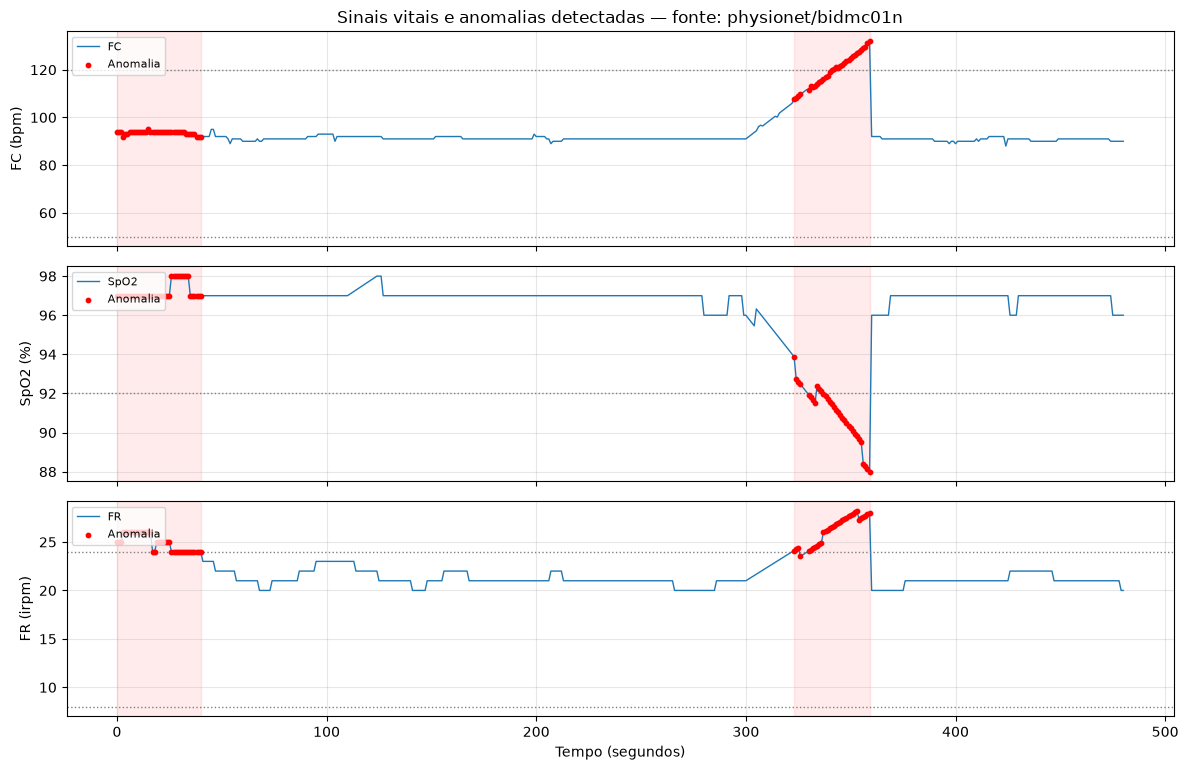

In [41]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(VARIAVEIS_VITAIS), 1, figsize=(12, 2.6 * len(VARIAVEIS_VITAIS)), sharex=True)
if len(VARIAVEIS_VITAIS) == 1:
    axes = [axes]

unidades = {"FC": "bpm", "SpO2": "%", "FR": "irpm", "PAS": "mmHg"}

for ax, var in zip(axes, VARIAVEIS_VITAIS):
    ax.plot(df_vitais["tempo_segundos"], df_vitais[var], linewidth=1, label=var)
    anomalos = df_vitais[df_vitais["anomalia"]]
    ax.scatter(anomalos["tempo_segundos"], anomalos[var], color="red", s=10, label="Anomalia", zorder=3)

    minimo, maximo = LIMITES_CLINICOS[var]
    ax.axhline(minimo, color="gray", linestyle=":", linewidth=1)
    if var != "SpO2":
        ax.axhline(maximo, color="gray", linestyle=":", linewidth=1)

    for _, ep in df_episodios_vitais.iterrows():
        ax.axvspan(ep["inicio_segundos"], ep["fim_segundos"], color="red", alpha=0.08)

    ax.set_ylabel(f"{var} ({unidades.get(var, '')})")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left", fontsize=8)

axes[0].set_title(f"Sinais vitais e anomalias detectadas — fonte: {df_vitais['fonte'].iloc[0]}")
axes[-1].set_xlabel("Tempo (segundos)")
plt.tight_layout()
plt.show()

### 4.2 Evolução de prescrições

O histórico de prescrições é analisado para identificar alterações inesperadas no tratamento:

- **Variação abrupta de dose** (acima de 50 % entre prescrições consecutivas do mesmo medicamento);
- **Suspensão abrupta** de medicamento de uso contínuo;
- **Introdução de medicamento de alta vigilância** (opioides, anticoagulantes, insulina, eletrólitos concentrados);
- **Alteração de frequência** de administração;
- **Dose fora da faixa usual** do medicamento, quando conhecida.

O conjunto de dados é simulado (não há base pública de prescrições individuais abertamente disponível),
mas o detector é independente da origem e pode ser aplicado a um extrato do prontuário eletrônico.

In [42]:
import pandas as pd

MEDICAMENTOS_ALTA_VIGILANCIA = [
    "morfina", "fentanil", "heparina", "enoxaparina", "varfarina",
    "insulina", "cloreto de potássio", "digoxina", "amiodarona", "noradrenalina"
]

# Faixas usuais de dose diária (mg) para referência experimental
FAIXA_DOSE_DIARIA = {
    "losartana": (25, 100),
    "metformina": (500, 2550),
    "dipirona": (500, 4000),
    "morfina": (5, 60),
    "enoxaparina": (20, 160),
    "omeprazol": (20, 40),
}

LIMIAR_VARIACAO_DOSE = 0.50

df_prescricoes = pd.DataFrame([
    # data,         medicamento,     dose_mg, frequencia_dia, via
    ("2026-10-01", "losartana",     50,  1, "oral"),
    ("2026-10-01", "metformina",    850, 2, "oral"),
    ("2026-10-01", "omeprazol",     20,  1, "oral"),
    ("2026-10-02", "losartana",     50,  1, "oral"),
    ("2026-10-02", "metformina",    850, 2, "oral"),
    ("2026-10-02", "omeprazol",     20,  1, "oral"),
    ("2026-10-03", "losartana",     50,  1, "oral"),
    ("2026-10-03", "metformina",    850, 2, "oral"),
    ("2026-10-03", "omeprazol",     20,  1, "oral"),
    ("2026-10-03", "dipirona",      500, 4, "oral"),
    ("2026-10-04", "losartana",     150, 1, "oral"),     # dose triplicada
    ("2026-10-04", "metformina",    850, 2, "oral"),
    ("2026-10-04", "omeprazol",     20,  1, "oral"),
    ("2026-10-04", "dipirona",      500, 4, "oral"),
    ("2026-10-05", "losartana",     150, 1, "oral"),
    ("2026-10-05", "omeprazol",     20,  1, "oral"),     # metformina suspensa
    ("2026-10-05", "dipirona",      500, 6, "oral"),     # frequência alterada
    ("2026-10-05", "morfina",       10,  4, "endovenosa"),  # alta vigilância
    ("2026-10-06", "losartana",     150, 1, "oral"),
    ("2026-10-06", "omeprazol",     20,  1, "oral"),
    ("2026-10-06", "dipirona",      500, 6, "oral"),
    ("2026-10-06", "morfina",       10,  4, "endovenosa"),
    ("2026-10-06", "enoxaparina",   40,  1, "subcutânea"),
], columns=["data", "medicamento", "dose_mg", "frequencia_dia", "via"])

df_prescricoes["data"] = pd.to_datetime(df_prescricoes["data"])
df_prescricoes["dose_diaria_mg"] = df_prescricoes["dose_mg"] * df_prescricoes["frequencia_dia"]
df_prescricoes = df_prescricoes.sort_values(["data", "medicamento"]).reset_index(drop=True)

display(df_prescricoes)

,data,medicamento,dose_mg,frequencia_dia,via,dose_diaria_mg
0,2026-10-01,losartana,50,1,oral,50
1,2026-10-01,metformina,850,2,oral,1700
2,2026-10-01,omeprazol,20,1,oral,20
3,2026-10-02,losartana,50,1,oral,50
4,2026-10-02,metformina,850,2,oral,1700
5,2026-10-02,omeprazol,20,1,oral,20
6,2026-10-03,dipirona,500,4,oral,2000
7,2026-10-03,losartana,50,1,oral,50
8,2026-10-03,metformina,850,2,oral,1700
9,2026-10-03,omeprazol,20,1,oral,20


In [43]:
def detectar_anomalias_prescricao(df):
    """Aplica regras de detecção de alterações inesperadas em prescrições."""
    alertas = []
    datas = sorted(df["data"].unique())
    medicamentos_vistos = set()

    for i, data in enumerate(datas):
        atuais = df[df["data"] == data].set_index("medicamento")
        anteriores = (
            df[df["data"] == datas[i - 1]].set_index("medicamento") if i > 0 else None
        )

        for med, linha in atuais.iterrows():
            # Medicamento novo
            if med not in medicamentos_vistos:
                medicamentos_vistos.add(med)
                if i > 0:
                    gravidade = "alta" if med in MEDICAMENTOS_ALTA_VIGILANCIA else "baixa"
                    alertas.append({
                        "data": data.date(), "medicamento": med,
                        "tipo": "Novo medicamento" + (" de alta vigilância" if gravidade == "alta" else ""),
                        "detalhe": f"{linha['dose_mg']} mg {linha['frequencia_dia']}x/dia ({linha['via']})",
                        "gravidade": gravidade,
                    })

            # Dose fora da faixa usual (alerta apenas quando a situação se inicia)
            if med in FAIXA_DOSE_DIARIA:
                minimo, maximo = FAIXA_DOSE_DIARIA[med]
                fora_da_faixa = not (minimo <= linha["dose_diaria_mg"] <= maximo)
                ja_estava_fora = (
                    anteriores is not None and med in anteriores.index
                    and not (minimo <= anteriores.loc[med, "dose_diaria_mg"] <= maximo)
                )
                if fora_da_faixa and not ja_estava_fora:
                    alertas.append({
                        "data": data.date(), "medicamento": med,
                        "tipo": "Dose diária fora da faixa usual",
                        "detalhe": f"{linha['dose_diaria_mg']} mg/dia (faixa {minimo}-{maximo})",
                        "gravidade": "alta",
                    })

            # Comparação com a prescrição anterior
            if anteriores is not None and med in anteriores.index:
                ant = anteriores.loc[med]
                if ant["dose_diaria_mg"] > 0:
                    variacao = (linha["dose_diaria_mg"] - ant["dose_diaria_mg"]) / ant["dose_diaria_mg"]
                    if abs(variacao) > LIMIAR_VARIACAO_DOSE:
                        alertas.append({
                            "data": data.date(), "medicamento": med,
                            "tipo": "Variação abrupta de dose",
                            "detalhe": f"{ant['dose_diaria_mg']} → {linha['dose_diaria_mg']} mg/dia ({variacao:+.0%})",
                            "gravidade": "alta" if abs(variacao) > 1.0 else "media",
                        })
                if linha["frequencia_dia"] != ant["frequencia_dia"]:
                    alertas.append({
                        "data": data.date(), "medicamento": med,
                        "tipo": "Alteração de frequência",
                        "detalhe": f"{ant['frequencia_dia']}x/dia → {linha['frequencia_dia']}x/dia",
                        "gravidade": "media",
                    })

        # Suspensão abrupta
        if anteriores is not None:
            for med in anteriores.index:
                if med not in atuais.index:
                    alertas.append({
                        "data": data.date(), "medicamento": med,
                        "tipo": "Suspensão abrupta",
                        "detalhe": f"Prescrito até {datas[i - 1].date()} e ausente em {data.date()}",
                        "gravidade": "media",
                    })

    return pd.DataFrame(
        alertas, columns=["data", "medicamento", "tipo", "detalhe", "gravidade"]
    )


df_alertas_prescricao = detectar_anomalias_prescricao(df_prescricoes)

print("=" * 50)
print("ANOMALIAS EM PRESCRIÇÕES")
print("=" * 50)
print(f"Prescrições analisadas: {len(df_prescricoes)}")
print(f"Alertas identificados : {len(df_alertas_prescricao)}")
display(df_alertas_prescricao)

ANOMALIAS EM PRESCRIÇÕES
Prescrições analisadas: 23
Alertas identificados : 7


,data,medicamento,tipo,detalhe,gravidade
0,2026-10-03,dipirona,Novo medicamento,500 mg 4x/dia (oral),baixa
1,2026-10-04,losartana,Dose diária fora da faixa usual,150 mg/dia (faixa 25-100),alta
2,2026-10-04,losartana,Variação abrupta de dose,50 → 150 mg/dia (+200%),alta
3,2026-10-05,dipirona,Alteração de frequência,4x/dia → 6x/dia,media
4,2026-10-05,morfina,Novo medicamento de alta vigilância,10 mg 4x/dia (endovenosa),alta
5,2026-10-05,metformina,Suspensão abrupta,Prescrito até 2026-10-04 e ausente em 2026-10-05,media
6,2026-10-06,enoxaparina,Novo medicamento de alta vigilância,40 mg 1x/dia (subcutânea),alta


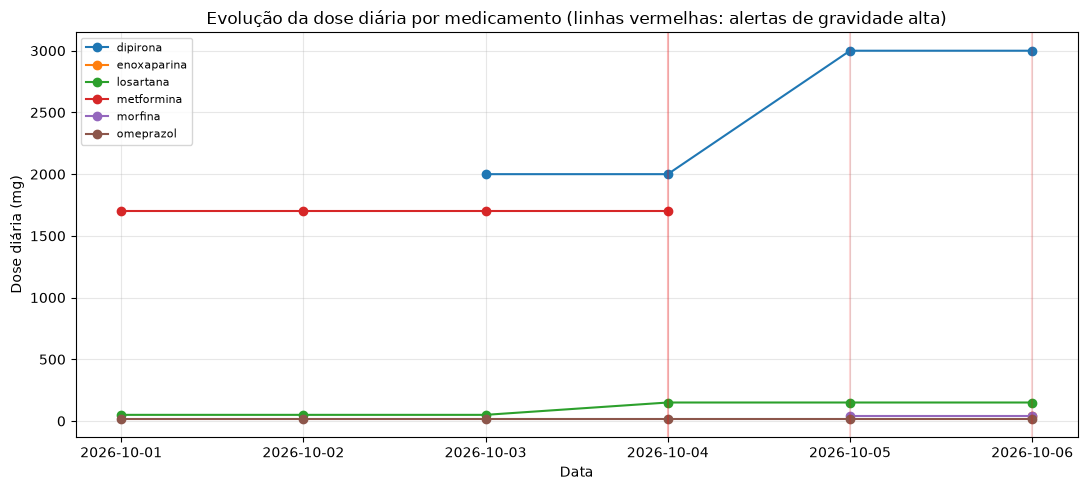

In [44]:
import matplotlib.pyplot as plt

tabela_doses = df_prescricoes.pivot_table(
    index="data", columns="medicamento", values="dose_diaria_mg", aggfunc="sum"
)

fig, ax = plt.subplots(figsize=(11, 5))
for med in tabela_doses.columns:
    ax.plot(tabela_doses.index, tabela_doses[med], marker="o", label=med)

for _, alerta in df_alertas_prescricao.iterrows():
    if alerta["gravidade"] == "alta":
        ax.axvline(pd.Timestamp(alerta["data"]), color="red", alpha=0.15)

ax.set_title("Evolução da dose diária por medicamento (linhas vermelhas: alertas de gravidade alta)")
ax.set_ylabel("Dose diária (mg)")
ax.set_xlabel("Data")
ax.legend(loc="upper left", fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Integração Multimodal e Geração de Alertas

As evidências de cada modalidade são consolidadas em uma estrutura única:

| Modalidade | Evidências |
|---|---|
| Vídeo | Desvios do procedimento (repetições, amplitude, ritmo, movimentação, eventos YOLOv8) |
| Áudio | Indicadores acústicos (velocidade da fala, pausas) |
| Texto | Sintomas não negados, categorias clínicas, sentimento (pysentimiento / Azure), entidades do Azure Health |
| Sinais vitais | Episódios anômalos (moderados e críticos) |
| Prescrições | Alertas de alteração no tratamento |

Um conjunto de regras de fusão atribui pontos a cada evidência e define o **nível de alerta**:

- **VERMELHO:** evidência crítica (episódio crítico de sinais vitais, relato de urgência alta ou
  possível queda) ou pontuação ≥ 8 com evidências em pelo menos três modalidades;
- **AMARELO:** pontuação ≥ 3;
- **VERDE:** demais casos.

In [45]:
import os
import json
from datetime import datetime

PACIENTE_ID = "PAC-0001"
cores = {"VERDE": "🟢", "AMARELO": "🟡", "VERMELHO": "🔴"}

# -----------------------------------------------------------------------------
# Texto: sintomas não negados e nível de urgência
# -----------------------------------------------------------------------------
CATEGORIA_SINTOMA = {
    "falta de ar": "respiratório",
    "dificuldade para respirar": "respiratório",
    "dor no peito": "cardiovascular",
    "palpitação": "cardiovascular",
    "tontura": "cardiovascular",
    "dor de cabeca": "neurológico",
    "cansaço": "geral",
    "alteração do sono": "geral",
    "sintoma aos esforços": "cardiovascular",
    "irradiação da dor": "cardiovascular",
    "desconforto abdominal": "geral",
    "tabagismo": "fator de risco",
    "histórico familiar cardíaco": "fator de risco",
}

sintomas_ativos = sorted({s["termo"] for s in sintomas_encontrados if s["status"] == "Menção identificada"})
sintomas_negados = sorted(
    {s["termo"] for s in sintomas_encontrados if s["status"] == "Menção negada"} - set(sintomas_ativos)
)
categorias = {CATEGORIA_SINTOMA.get(s, "geral") for s in sintomas_ativos}
categorias_criticas = categorias & {"respiratório", "cardiovascular", "neurológico"}
fatores_risco = [s for s in sintomas_ativos if CATEGORIA_SINTOMA.get(s) == "fator de risco"]

# Dor torácica relacionada ao esforço ou com irradiação: padrão sugestivo de síndrome coronariana
padrao_anginoso = "dor no peito" in sintomas_ativos and (
    {"sintoma aos esforços", "irradiação da dor"} & set(sintomas_ativos)
)

if len(categorias_criticas) >= 2 or padrao_anginoso:
    nivel_urgencia = "alto"
elif categorias_criticas or len(sintomas_ativos) >= 3:
    nivel_urgencia = "medio"
else:
    nivel_urgencia = "baixo"

mapa_sentimento = {"NEG": "negativo", "POS": "positivo", "NEU": "neutro"}
sentimento_final = resultado_azure.get("sentimento") or mapa_sentimento[resultado_sentimento.output]
sentimento_final = {"negative": "negativo", "positive": "positivo",
                    "neutral": "neutro", "mixed": "misto"}.get(sentimento_final, sentimento_final)

# -----------------------------------------------------------------------------
# Áudio: indicadores acústicos (limites experimentais)
# -----------------------------------------------------------------------------
alertas_voz = []
if indicadores_acusticos["velocidade_fala_palavras_min"] < 110:
    alertas_voz.append("Fala lenta (possível fadiga)")
if indicadores_acusticos["proporcao_sem_atividade"] > 0.35:
    alertas_voz.append("Pausas frequentes (possível dificuldade respiratória)")
if indicadores_acusticos["maior_pausa_segundos"] > 2.0:
    alertas_voz.append("Pausa prolongada na fala")

# -----------------------------------------------------------------------------
# Consolidação das evidências de cada modalidade
# -----------------------------------------------------------------------------
evidencias = {
    "video": {
        "arquivos": list(execucoes.keys()),
        "resumo_execucoes": df_comparacao.to_dict(orient="records"),
        "desvios": df_desvios.to_dict(orient="records"),
        "objetos_detectados": objetos_cena,
        "avaliacao_rotulos": resultado_avaliacao_video,
    },
    "audio": {
        "arquivo": arquivo_audio_paciente,
        "indicadores_acusticos": indicadores_acusticos,
        "alertas_vocais": alertas_voz,
    },
    "texto": {
        "transcricao_paciente": transcricao_paciente.strip(),
        "sintomas": sintomas_ativos,
        "sintomas_negados": sintomas_negados,
        "categorias": sorted(categorias),
        "padrao_anginoso": bool(padrao_anginoso),
        "fatores_risco": fatores_risco,
        "modo_audio": MODO_AUDIO,
        "separacao_locutores": metodo_separacao,
        "sentimento": sentimento_final,
        "nivel_urgencia": nivel_urgencia,
        "entidades_azure": resultado_azure.get("entidades_saude", []),
    },
    "sinais_vitais": {
        "fonte": str(df_vitais["fonte"].iloc[0]),
        "amostras": int(len(df_vitais)),
        "episodios": df_episodios_vitais.to_dict(orient="records"),
        "episodios_criticos": int((df_episodios_vitais["gravidade"] == "crítica").sum())
        if not df_episodios_vitais.empty else 0,
    },
    "prescricoes": {
        "prescricoes_analisadas": int(len(df_prescricoes)),
        "alertas": df_alertas_prescricao.assign(
            data=df_alertas_prescricao["data"].astype(str)
        ).to_dict(orient="records"),
        "alertas_gravidade_alta": int((df_alertas_prescricao["gravidade"] == "alta").sum()),
    },
    "azure": {k: v for k, v in resultado_azure.items() if k != "entidades_saude"},
}

# -----------------------------------------------------------------------------
# Regras de fusão
# -----------------------------------------------------------------------------
PESOS = {
    "video_desvio_baixo": 0.5,
    "video_desvio_medio": 1,
    "video_desvio_alto": 2,
    "audio_alerta_vocal": 1,
    "texto_urgencia_media": 2,
    "texto_urgencia_alta": 4,
    "texto_sentimento_negativo": 1,
    "vitais_episodio_moderado": 2,
    "vitais_episodio_critico": 4,
    "prescricao_alerta_media": 1,
    "prescricao_alerta_alta": 2,
}


def fundir_evidencias(ev):
    pontos = 0.0
    justificativas = []
    modalidades_ativas = set()
    critico = False

    # Vídeo
    for d in ev["video"]["desvios"]:
        peso = PESOS.get(f"video_desvio_{d['gravidade']}", 1)
        pontos += peso
        modalidades_ativas.add("vídeo")
        if d["tipo"] == "Possível queda":
            critico = True
        if d["gravidade"] in ("media", "alta"):
            justificativas.append(f"vídeo ({d['origem']}): {d['tipo']}")
    n_baixos = sum(1 for d in ev["video"]["desvios"] if d["gravidade"] == "baixa")
    if n_baixos:
        justificativas.append(f"vídeo: {n_baixos} desvio(s) de baixa gravidade")

    # Áudio
    if ev["audio"]["alertas_vocais"]:
        pontos += PESOS["audio_alerta_vocal"] * len(ev["audio"]["alertas_vocais"])
        modalidades_ativas.add("áudio")
        justificativas.append("indicadores vocais: " + "; ".join(ev["audio"]["alertas_vocais"]))

    # Texto
    urg = ev["texto"]["nivel_urgencia"]
    if urg == "medio":
        pontos += PESOS["texto_urgencia_media"]
        modalidades_ativas.add("texto")
        justificativas.append("relato com urgência média: " + ", ".join(ev["texto"]["sintomas"]))
    elif urg == "alto":
        pontos += PESOS["texto_urgencia_alta"]
        modalidades_ativas.add("texto")
        critico = True
        motivo = " (padrão sugestivo de dor anginosa)" if ev["texto"]["padrao_anginoso"] else ""
        justificativas.append("relato com urgência alta" + motivo + ": " + ", ".join(ev["texto"]["sintomas"]))
    if ev["texto"]["fatores_risco"]:
        justificativas.append("fatores de risco relatados: " + ", ".join(ev["texto"]["fatores_risco"]))
    if ev["texto"]["sentimento"] == "negativo":
        pontos += PESOS["texto_sentimento_negativo"]
        justificativas.append("sentimento negativo no relato")

    # Sinais vitais
    for ep in ev["sinais_vitais"]["episodios"]:
        if ep["gravidade"] == "crítica":
            pontos += PESOS["vitais_episodio_critico"]
            critico = True
            justificativas.append(
                f"episódio crítico de sinais vitais em {ep['inicio_segundos']}-{ep['fim_segundos']} s "
                f"({ep['variaveis_fora_do_limite']})"
            )
        else:
            pontos += PESOS["vitais_episodio_moderado"]
            justificativas.append(
                f"episódio moderado de sinais vitais em {ep['inicio_segundos']}-{ep['fim_segundos']} s"
            )
        modalidades_ativas.add("sinais vitais")

    # Prescrições
    for al in ev["prescricoes"]["alertas"]:
        if al["gravidade"] == "alta":
            pontos += PESOS["prescricao_alerta_alta"]
            justificativas.append(f"prescrição: {al['tipo']} — {al['medicamento']} ({al['detalhe']})")
        elif al["gravidade"] == "media":
            pontos += PESOS["prescricao_alerta_media"]
        modalidades_ativas.add("prescrições")

    # Decisão
    if critico or (pontos >= 8 and len(modalidades_ativas) >= 3):
        nivel = "VERMELHO"
    elif pontos >= 3:
        nivel = "AMARELO"
    else:
        nivel = "VERDE"

    return {
        "nivel": nivel,
        "pontuacao": round(pontos, 1),
        "modalidades_com_evidencia": sorted(modalidades_ativas),
        "justificativas": justificativas,
    }


decisao = fundir_evidencias(evidencias)

alerta_final = {
    "paciente_id": PACIENTE_ID,
    "gerado_em": datetime.now().isoformat(timespec="seconds"),
    "nivel_alerta": decisao["nivel"],
    "pontuacao": decisao["pontuacao"],
    "modalidades_com_evidencia": decisao["modalidades_com_evidencia"],
    "justificativas": decisao["justificativas"],
    "evidencias": evidencias,
}

print("=" * 50)
print("ALERTA CONSOLIDADO")
print("=" * 50)
print(f"Paciente   : {PACIENTE_ID}")
print(f"Nível      : {cores[decisao['nivel']]} {decisao['nivel']} (pontuação {decisao['pontuacao']})")
print(f"Modalidades: {', '.join(decisao['modalidades_com_evidencia']) or 'nenhuma'}")
print("Justificativas:")
for j in decisao["justificativas"]:
    print(f" - {j}")

ALERTA CONSOLIDADO
Paciente   : PAC-0001
Nível      : 🔴 VERMELHO (pontuação 31.0)
Modalidades: prescrições, sinais vitais, texto, vídeo
Justificativas:
 - vídeo (amplitude articular): Amplitude incompleta (107.0° < 127°)
 - vídeo (amplitude articular): Amplitude incompleta (102.9° < 127°)
 - vídeo (amplitude articular): Amplitude incompleta (123.6° < 127°)
 - vídeo (amplitude articular): Amplitude incompleta (124.6° < 127°)
 - vídeo (amplitude articular): Amplitude incompleta (118.7° < 127°)
 - vídeo (amplitude articular): Amplitude incompleta (119.2° < 127°)
 - vídeo (amplitude articular): Amplitude incompleta (121.6° < 127°)
 - vídeo: 1 desvio(s) de baixa gravidade
 - relato com urgência alta (padrão sugestivo de dor anginosa): desconforto abdominal, dor no peito, irradiação da dor, sintoma aos esforços, tabagismo
 - fatores de risco relatados: tabagismo
 - sentimento negativo no relato
 - episódio crítico de sinais vitais em 0.0-40.0 s (FR)
 - episódio crítico de sinais vitais em 32

### 5.1 Envio do alerta à equipe médica

A função `enviar_alerta_equipe` representa o ponto de integração com os canais da equipe
(painel de enfermagem, Teams/Slack, SMS). Por padrão o alerta é apenas exibido e registrado em
arquivo; se `WEBHOOK_URL` for configurada (ex.: *Incoming Webhook* do Microsoft Teams ou Slack),
a mensagem é enviada por HTTP POST.

In [46]:
import os
import json
import requests

WEBHOOK_URL = os.getenv("WEBHOOK_URL", "")   # ex.: https://hooks.slack.com/services/...
ARQUIVO_LOG_ALERTAS = "alertas_enviados.jsonl"


def formatar_mensagem_alerta(alerta):
    linhas = [
        f"{cores[alerta['nivel_alerta']]} ALERTA {alerta['nivel_alerta']} — Paciente {alerta['paciente_id']}",
        f"Gerado em: {alerta['gerado_em']}",
        f"Modalidades: {', '.join(alerta['modalidades_com_evidencia']) or 'nenhuma'}",
        "Evidências:",
    ]
    linhas += [f"  • {j}" for j in alerta["justificativas"]] or ["  • nenhuma"]
    return "\n".join(linhas)


def enviar_alerta_equipe(alerta, webhook_url=WEBHOOK_URL):
    mensagem = formatar_mensagem_alerta(alerta)

    # Registro local (auditoria)
    with open(ARQUIVO_LOG_ALERTAS, "a", encoding="utf-8") as f:
        f.write(json.dumps(
            {k: v for k, v in alerta.items() if k != "evidencias"}, ensure_ascii=False
        ) + "\n")

    # Canal externo (opcional)
    status_envio = "registrado localmente"
    if webhook_url:
        try:
            resposta = requests.post(webhook_url, json={"text": mensagem}, timeout=10)
            status_envio = f"enviado ao webhook (HTTP {resposta.status_code})"
        except Exception as erro:
            status_envio = f"falha no envio ao webhook: {erro}"

    print(mensagem)
    print("-" * 50)
    print(f"Status: {status_envio}")
    return status_envio


if alerta_final["nivel_alerta"] in ("AMARELO", "VERMELHO"):
    enviar_alerta_equipe(alerta_final)
else:
    print("Nível verde: nenhum alerta enviado à equipe.")

🔴 ALERTA VERMELHO — Paciente PAC-0001
Gerado em: 2026-11-17T20:48:45
Modalidades: prescrições, sinais vitais, texto, vídeo
Evidências:
  • vídeo (amplitude articular): Amplitude incompleta (107.0° < 127°)
  • vídeo (amplitude articular): Amplitude incompleta (102.9° < 127°)
  • vídeo (amplitude articular): Amplitude incompleta (123.6° < 127°)
  • vídeo (amplitude articular): Amplitude incompleta (124.6° < 127°)
  • vídeo (amplitude articular): Amplitude incompleta (118.7° < 127°)
  • vídeo (amplitude articular): Amplitude incompleta (119.2° < 127°)
  • vídeo (amplitude articular): Amplitude incompleta (121.6° < 127°)
  • vídeo: 1 desvio(s) de baixa gravidade
  • relato com urgência alta (padrão sugestivo de dor anginosa): desconforto abdominal, dor no peito, irradiação da dor, sintoma aos esforços, tabagismo
  • fatores de risco relatados: tabagismo
  • sentimento negativo no relato
  • episódio crítico de sinais vitais em 0.0-40.0 s (FR)
  • episódio crítico de sinais vitais em 323.0-

### 5.2 Simulação de monitoramento em tempo real

Para demonstrar a detecção **em tempo real**, a série de sinais vitais é reproduzida amostra a
amostra como um fluxo contínuo. A cada nova leitura o detector utiliza apenas o histórico recebido
até aquele instante (janela móvel + limites clínicos) e dispara o alerta assim que a anomalia
persiste por algumas leituras consecutivas, sem conhecimento do futuro da série.

In [47]:
import time
from collections import deque


def simular_monitoramento_tempo_real(df, variaveis, janela=60, limiar_z=3.0,
                                     persistencia=5, atraso_segundos=0.0, max_alertas=10):
    """Reproduz a série como fluxo e alerta quando a anomalia persiste por
    `persistencia` leituras consecutivas (evita disparos por ruído pontual)."""
    historico = {var: deque(maxlen=janela) for var in variaveis}
    em_alerta = False
    leituras_suspeitas = 0
    alertas_emitidos = []

    for _, leitura in df.iterrows():
        t = leitura["tempo_segundos"]
        motivos = []

        for var in variaveis:
            valor = leitura[var]
            minimo, maximo = LIMITES_CLINICOS[var]

            if valor < minimo or valor > maximo:
                motivos.append(f"{var}={valor:.0f} fora de [{minimo}, {maximo}]")
            elif len(historico[var]) >= 10:
                media = np.mean(historico[var])
                desvio = np.std(historico[var]) or 1e-9
                z = abs(valor - media) / desvio
                if z > limiar_z:
                    motivos.append(f"{var}={valor:.0f} (z={z:.1f})")

        # Apenas leituras normais atualizam a janela de referência do paciente
        if not motivos:
            for var in variaveis:
                historico[var].append(leitura[var])

        leituras_suspeitas = leituras_suspeitas + 1 if motivos else 0

        if leituras_suspeitas >= persistencia and not em_alerta:
            em_alerta = True
            alertas_emitidos.append({"tempo_segundos": t, "motivos": motivos})
            print(f"[t={t:7.1f}s] 🔴 ALERTA iniciado: {'; '.join(motivos)}")
            if len(alertas_emitidos) >= max_alertas:
                break
        elif not motivos and em_alerta:
            em_alerta = False
            print(f"[t={t:7.1f}s] 🟢 Parâmetros normalizados")

        if atraso_segundos:
            time.sleep(atraso_segundos)

    print("-" * 50)
    print(f"Alertas em tempo real emitidos: {len(alertas_emitidos)}")
    return alertas_emitidos


alertas_tempo_real = simular_monitoramento_tempo_real(df_vitais, VARIAVEIS_VITAIS)

[t=    4.0s] 🔴 ALERTA iniciado: FR=26 fora de [8, 24]
[t=   41.0s] 🟢 Parâmetros normalizados
[t=  115.0s] 🔴 ALERTA iniciado: SpO2=97 (z=357142857.1)
[t=  127.0s] 🟢 Parâmetros normalizados
[t=  270.0s] 🔴 ALERTA iniciado: FR=20 (z=3.9)
[t=  292.0s] 🟢 Parâmetros normalizados
[t=  303.0s] 🔴 ALERTA iniciado: FC=93 (z=2033898305.1); SpO2=96 (z=1406779661.0); FR=21 (z=406779661.0)
[t=  376.0s] 🟢 Parâmetros normalizados
[t=  394.0s] 🔴 ALERTA iniciado: FC=90 (z=1000000000.0)
[t=  410.0s] 🟢 Parâmetros normalizados
[t=  420.0s] 🔴 ALERTA iniciado: FC=92 (z=1000000000.0)
[t=  425.0s] 🟢 Parâmetros normalizados
[t=  430.0s] 🔴 ALERTA iniciado: FR=22 (z=999969484.5)
[t=  449.0s] 🟢 Parâmetros normalizados
[t=  478.0s] 🔴 ALERTA iniciado: FC=90 (z=1000000000.0); SpO2=96 (z=1000000000.0)
--------------------------------------------------
Alertas em tempo real emitidos: 8


### 5.3 Relatório automático

Os resultados de todas as modalidades são consolidados em dois arquivos:

- `relatorio_alertas.json`: estrutura completa (evidências + decisão), para integração com sistemas;
- `relatorio_tecnico.md`: relatório legível com fluxo multimodal, modelos aplicados e anomalias
  detectadas, que serve de base para o relatório técnico exigido na entrega.

In [48]:
import json

with open("relatorio_alertas.json", "w", encoding="utf-8") as f:
    json.dump(alerta_final, f, ensure_ascii=False, indent=2, default=str)


def gerar_relatorio_markdown(alerta):
    ev = alerta["evidencias"]
    linhas = [
        "# Relatório de Monitoramento Multimodal",
        "",
        f"- **Paciente:** {alerta['paciente_id']}",
        f"- **Gerado em:** {alerta['gerado_em']}",
        f"- **Nível de alerta:** {alerta['nivel_alerta']} (pontuação {alerta['pontuacao']})",
        f"- **Modalidades com evidência:** {', '.join(alerta['modalidades_com_evidencia']) or 'nenhuma'}",
        "",
        "## 1. Fluxo multimodal",
        "",
        "Vídeo → MediaPipe Pose (repetições, ângulo do ombro, movimentação) + YOLOv8 (objetos, área de exercício, queda) → relatório de desvios.",
        "",
        "Áudio → Whisper e Azure Speech to Text (transcrição) → librosa (velocidade, pausas, pitch, energia).",
        "",
        "Texto → regras com negação + pysentimiento + Azure AI Language (sentimento e Text Analytics for Health).",
        "",
        "Dados clínicos → limites clínicos + escore-z móvel + Isolation Forest (sinais vitais PhysioNet); regras de variação (prescrições).",
        "",
        "Fusão → regras ponderadas → nível de alerta → notificação à equipe.",
        "",
        "## 2. Modelos aplicados",
        "",
        "| Dado | Modelo / técnica |",
        "|---|---|",
        "| Vídeo | MediaPipe Pose Landmarker (lite), YOLOv8s, regras geométricas, Isolation Forest |",
        "| Áudio | OpenAI Whisper (small), Azure AI Speech, librosa |",
        "| Texto | Regras com negação, pysentimiento, Azure AI Language (sentimento, Health) |",
        "| Sinais vitais | Limites clínicos, escore-z móvel, Isolation Forest |",
        "| Prescrições | Regras de variação de dose/frequência/suspensão |",
        "",
        "## 3. Resultados",
        "",
        "### Vídeo",
    ]
    for r in ev["video"]["resumo_execucoes"]:
        linhas.append(
            f"- `{r['video']}`: {r['repeticoes']} repetições ({r['validas']} válidas), "
            f"ângulo máximo médio {r['angulo_max_medio']}°, CV do ritmo {r['cv_ritmo']}"
        )
    linhas.append(f"- Objetos detectados (YOLOv8): {', '.join(ev['video']['objetos_detectados']) or 'nenhum'}")
    av = ev["video"].get("avaliacao_rotulos") or {}
    if av:
        linhas.append(
            f"- Avaliação contra rótulos do fisioterapeuta (`{av['video']}`): precisão {av['precisao']:.0%}, "
            f"revocação {av['revocacao']:.0%}, acurácia {av['acuracia']:.0%} "
            f"(VP={av['vp']}, FP={av['fp']}, FN={av['fn']}, VN={av['vn']})"
        )
    linhas.append(f"- Desvios do procedimento: {len(ev['video']['desvios'])}")
    for d in ev["video"]["desvios"]:
        linhas.append(f"  - [{d['gravidade']}] {d['origem']}: {d['tipo']}")
    linhas += [
        "",
        "### Áudio e texto",
        f"- Transcrição do paciente: _{ev['texto']['transcricao_paciente']}_",
        f"- Velocidade da fala: {ev['audio']['indicadores_acusticos']['velocidade_fala_palavras_min']} palavras/min",
        f"- Alertas vocais: {', '.join(ev['audio']['alertas_vocais']) or 'nenhum'}",
        f"- Sintomas relatados: {', '.join(ev['texto']['sintomas']) or 'nenhum'}",
        f"- Sintomas negados: {', '.join(ev['texto']['sintomas_negados']) or 'nenhum'}",
        f"- Sentimento: {ev['texto']['sentimento']} | Urgência: {ev['texto']['nivel_urgencia']}",
    ]
    if ev["azure"].get("comparacao_stt"):
        for c in ev["azure"]["comparacao_stt"]:
            linhas.append(f"- WER {c['modelo']}: {c['WER']}")
    if ev["texto"]["entidades_azure"]:
        linhas.append("- Entidades clínicas (Azure Health): " + ", ".join(
            f"{e['texto']} ({e['categoria']}, {e['assercao']})" for e in ev["texto"]["entidades_azure"]))
    linhas += [
        "",
        "### Sinais vitais",
        f"- Fonte: {ev['sinais_vitais']['fonte']} ({ev['sinais_vitais']['amostras']} amostras)",
        f"- Episódios anômalos: {len(ev['sinais_vitais']['episodios'])} "
        f"(críticos: {ev['sinais_vitais']['episodios_criticos']})",
    ]
    for ep in ev["sinais_vitais"]["episodios"]:
        linhas.append(
            f"  - {ep['inicio_segundos']}–{ep['fim_segundos']} s, {ep['gravidade']}, "
            f"variáveis fora do limite: {ep['variaveis_fora_do_limite']}"
        )
    linhas += [
        "",
        "### Prescrições",
        f"- Prescrições analisadas: {ev['prescricoes']['prescricoes_analisadas']}",
        f"- Alertas: {len(ev['prescricoes']['alertas'])} (gravidade alta: {ev['prescricoes']['alertas_gravidade_alta']})",
    ]
    for al in ev["prescricoes"]["alertas"]:
        linhas.append(f"  - {al['data']}: {al['tipo']} — {al['medicamento']} ({al['detalhe']})")
    linhas += ["", "## 4. Decisão e justificativas", ""]
    linhas += [f"- {j}" for j in alerta["justificativas"]] or ["- Sem evidências relevantes."]
    linhas += [
        "",
        "---",
        "_Os alertas são indicadores experimentais de apoio à equipe e não constituem diagnóstico clínico._",
    ]
    return "\n".join(linhas)


relatorio_md = gerar_relatorio_markdown(alerta_final)
with open("relatorio_tecnico.md", "w", encoding="utf-8") as f:
    f.write(relatorio_md)

print("Arquivos gerados: relatorio_alertas.json, relatorio_tecnico.md")
print("=" * 50)
print(relatorio_md)

Arquivos gerados: relatorio_alertas.json, relatorio_tecnico.md
# Relatório de Monitoramento Multimodal

- **Paciente:** PAC-0001
- **Gerado em:** 2026-11-17T20:48:45
- **Nível de alerta:** VERMELHO (pontuação 31.0)
- **Modalidades com evidência:** prescrições, sinais vitais, texto, vídeo

## 1. Fluxo multimodal

Vídeo → MediaPipe Pose (repetições, ângulo do ombro, movimentação) + YOLOv8 (objetos, área de exercício, queda) → relatório de desvios.

Áudio → Whisper e Azure Speech to Text (transcrição) → librosa (velocidade, pausas, pitch, energia).

Texto → regras com negação + pysentimiento + Azure AI Language (sentimento e Text Analytics for Health).

Dados clínicos → limites clínicos + escore-z móvel + Isolation Forest (sinais vitais PhysioNet); regras de variação (prescrições).

Fusão → regras ponderadas → nível de alerta → notificação à equipe.

## 2. Modelos aplicados

| Dado | Modelo / técnica |
|---|---|
| Vídeo | MediaPipe Pose Landmarker (lite), YOLOv8s, regras geométricas, Isol

## 6. Considerações finais

A prova de conceito cobre os três requisitos obrigatórios do Tech Challenge:

1. **Análise de vídeo** — análise postural com MediaPipe Pose (repetições, ângulo de flexão do
   ombro, ritmo e padrões de movimentação), detecção de objetos e eventos de cena com YOLOv8
   (área de exercício, ausência, possível queda) e relatório automático de desvios.
2. **Análise de áudio** — transcrição com Whisper e **Azure Speech to Text**, indicadores acústicos
   de fadiga e dificuldade respiratória, termos críticos com negação e sentimento com pysentimiento
   e **Azure AI Language** (sentimento e Text Analytics for Health).
3. **Detecção de anomalias** — sinais vitais do PhysioNet (limites clínicos, escore-z móvel,
   Isolation Forest, com validação por episódio injetado), evolução de prescrições e padrões de
   movimentação, com fusão das evidências, alerta em tempo real e notificação à equipe.

### Limitações

- Os limiares são experimentais e devem ser calibrados com dados reais e validação clínica.
- O áudio da consulta é uma simulação de OSCE (atores), e não um paciente real; no modo
  `sintetico`, os indicadores vocais descrevem a voz artificial do Edge-TTS.
- Sem Azure, a separação médico/paciente usa uma heurística simples (perguntas = médico).
- O histórico de prescrições é simulado e o episódio de sinais vitais é injetado em dados reais.
- O limiar de abdução (127°) foi calibrado com os rótulos do próprio vídeo do REHAB24-6; a
  avaliação mostra a capacidade de separação da métrica, não uma validação independente.
- Os vídeos de flexão (grupo) e de abdução (REHAB24-6) são de pessoas diferentes; a fusão os trata
  como sessões de um mesmo paciente apenas para fins de demonstração.
- Nenhum resultado constitui diagnóstico; o sistema é um apoio à triagem e ao monitoramento.

### Arquivos gerados

| Arquivo | Conteúdo |
|---|---|
| `video_pose_classificado.mp4` | Vídeo com esqueleto e classificação das repetições |
| `video_yolo.mp4` / `yolo_quadro_exemplo.jpg` | Detecções do YOLOv8 |
| `relatorio_desvios_video.md` | Desvios do procedimento |
| `resultado_audio_completo.json` | Resultados da análise de áudio |
| `relatorio_alertas.json` | Evidências e decisão consolidadas |
| `relatorio_tecnico.md` | Relatório técnico automático |
| `alertas_enviados.jsonl` | Log de alertas enviados à equipe |

In [49]:
# Download dos artefatos gerados (apenas no Colab)
if files is not None:
    for arquivo in [
        "video_pose_classificado.mp4",
        "video_yolo.mp4",
        "relatorio_desvios_video.md",
        "relatorio_alertas.json",
        "relatorio_tecnico.md",
        "alertas_enviados.jsonl",
    ]:
        if os.path.exists(arquivo):
            files.download(arquivo)
else:
    print("Fora do Colab: os arquivos estão no diretório de trabalho.")

Fora do Colab: os arquivos estão no diretório de trabalho.
